# Case 3 — Nudge Campaign A/B Test: Did the Nudges *Cause* the Uplift, How Big Is It, and Which Channel and Segment Should We Fund?

**Reference:** Case Study 22 — *Axis Bank: An Omnichannel Nudge Engine That Books Deposits and Loans* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Marketing, Digital Banking, Retail Lending, Finance (campaign budget)
**Data:** ⚠️ **SEMI-SYNTHETIC.** The customer attributes (age, job, marital status, education, prior loans, prior campaign response, balance rank) come from the public **UCI Bank Marketing** dataset (CC BY 4.0), bootstrapped to 200,000 customers. **The randomised experiment, all Indian-context attributes and all outcomes are synthetic**, because the UCI data has no treatment/control (D-3-01). These are not Axis Bank's data.
**Reproducibility:** seed = 42. Run with `python -m nbconvert --to notebook --execute --inplace 03_nudge_campaign_ab_test.ipynb`.

## 0. Executive Summary for Business

*(Written last; customer attributes from the public UCI Bank Marketing data; experiment and outcomes simulated to Axis Bank's documented figures.)*

- **The problem:** Marketing credits the Diwali nudges with more BillPay registrations and personal loans. We used the 20% randomly held-back customers to test whether the nudges *caused* the uplift.
- **BillPay:** the nudges caused **1.53× more registrations** (3.7% → 5.7%; 95% CI 1.45–1.61×), matching Axis's documented 1.5×.
- **Personal loans:** **10% more customers borrowed** (2.47% → 2.73%; p = 0.005; CI +3% to +18%), matching the documented +10%. **Loan sizes did not change** (≈ ₹4.7 lakh average in both groups).
- **₹ impact:** +₹119 revenue per nudged customer (CI ₹26–213), so **≈ ₹1.9 crore of incremental revenue for ≈ ₹8 lakh of campaign cost**: ROI ≈ 23×, and still ≈ 3× in the worst case.
- **Channels:** **Push (app users only) and WhatsApp drive the BillPay lift**, at ₹111 and ₹279 per extra registration vs ₹408–537 for Email and SMS. For loans, channel differences are too small to prove with this sample.
- **A data trap we caught:** Marketing's tracking export silently dropped 2,608 Push customers, which made Push look better than it is. We fixed it by analysing the full randomised list.
- **I recommend:** keep funding; send Push to app users and WhatsApp to everyone else; target the highest-uplift customers (the top 40% delivers 57% of the effect); keep a permanent hold-out with a daily data check; and confirm the new allocation in the next randomised wave.

## 1. The Problem in Simple English

Over Diwali, the bank sent personalised nudges to its customers: an SMS, an email, a WhatsApp message or an app push notification, suggesting they register for **BillPay** (pay electricity, mobile and DTH bills from the bank app) or take a pre-approved **personal loan**. Marketing reports that registrations and loan bookings went up during the campaign.

The question from the business is sharper: **did the nudges *cause* the uplift, or would those customers have registered and borrowed anyway?** Diwali is peak season for both bill payments and personal loans, so "bookings went up" proves nothing on its own.

That is why one in five customers was **randomly held back** (the *control group*) and received no nudge. Because the split was random, the control group is a fair picture of what *would have happened anyway*. The difference between the two groups is the **causal effect** of the nudges.

What the business needs to know:

1. **Did it work?** Is the lift real or noise, and how big is it, in registrations, loans and ₹?
2. **Which channel works best,** per rupee spent?
3. **For whom does it work?** Which segments should we target next time, without fooling ourselves by slicing the data until something looks good?
4. **Can we trust the experiment itself?** Was the control group big enough, and was the data logged correctly?

## 2. Reference from the Case File

### (a) What Axis Bank actually did — *documented* (quoted from the reference file)

| Item | Documented fact |
|---|---|
| Business problem | "Move from product-push campaigns to customer-centric, personalised marketing across 50M+ customers." |
| Business question | "For each customer: which product, which channel, which message, and when?" |
| Data | "2,000+ customer attributes updated daily: demographics, transactions, browsing, preferences"; 50M+ customers |
| Approach | ML models for **channel and product optimisation**; segmentation across 10 business lines; **17,000+ nudge variants**; a "Control Tower" for campaign tracking; **test vs control** measurement |
| Channels | "9, including SMS, email, push, WhatsApp, in-app banners" |
| Statistics | "Test vs control comparison (e.g., BillPay '1.5x boost in test versus control'). Significance testing: ND." (not disclosed) |
| Models | "Advanced ML models"; algorithms ND |
| Impact | "45% of the term deposits and 70% of instant loans on credit cards are booked via personalized nudges"; "Personal-loan campaign effectiveness **+10%**"; "BillPay registration **1.5x** (test vs control)" |
| Learning note (interpretation in the file) | "Hold-out control groups turn 'campaign performance' into causal lift. Without them, you only measure who would have bought anyway." "'Share of bookings via nudges' shows adoption but is not causal on its own." |

**Source:** Cloudera customer story, Axis Bank (4 Feb 2025), quoting Balaji Narayanamurthy, Head of Business Intelligence — https://www.cloudera.com/customers/axis-bank.html

### (b) What *we* are simulating or adding — *our professional approach*

| Item | Our choice |
|---|---|
| Customers | 200,000, built from real UCI Bank Marketing attributes plus synthetic Indian context (city tier, tenure, income band, app activity, pre-period behaviour) |
| Experiment | Customer-level randomisation: **80% treatment / 20% control**; treatment customers randomly assigned to SMS, Email, WhatsApp or Push; campaign 1 Oct – 30 Nov 2025 (spans Diwali) |
| Outcomes | BillPay registration, PL booking, PL amount (₹), calibrated to the documented **1.5×** and **+10%** |
| Built-in realism | channel × segment heterogeneity (push only reaches app users), Diwali-week seasonality, missing covariates, a ₹-unit error, and **one sample-ratio-mismatch (SRM) logging bug** to detect |
| Statistics added | SRM test, covariate balance, Z-tests with CIs, Welch t / Mann–Whitney, bootstrap, ANOVA / Kruskal–Wallis + Tukey / Dunn–Holm, CUPED, power analysis, heterogeneity with multiple-testing control |
| ML | T-learner uplift model (two logistic regressions) + Qini curve |
| Business layer | incremental registrations and loans → ₹ revenue − campaign cost → ROI per channel and budget reallocation |

## 3. Business Question → Analytical Question → Statistical Hypotheses

Fixed **before** looking at outcomes.

| Level | Statement |
|---|---|
| **Business question** | Should we keep funding the nudge programme, and how should the budget be split across channels and segments? |
| **Analytical Q1** | Is the experiment valid (correct split, balanced groups)? |
| **Analytical Q2** | What is the causal effect of being nudged on BillPay registration, PL booking, PL amount and revenue per customer? |
| **Analytical Q3** | Do the channels differ in effect? |
| **Analytical Q4** | Does the effect differ by customer segment? |

**Statistical hypotheses**

- **H0 (SRM):** the observed treatment:control split = the designed 80:20. Chi-square goodness-of-fit, α = 0.001 (D-3-08).
- **H1 (BillPay):** H0: p_T = p_C vs H1: p_T ≠ p_C. Two-proportion Z-test.
- **H2 (PL conversion):** H0: q_T = q_C vs H1: q_T ≠ q_C. Two-proportion Z-test.
- **H3 (PL amount, among bookers):** H0: equal mean amounts (Welch t-test) / equal distributions (Mann–Whitney U).
- **H4 (revenue per customer):** H0: equal mean revenue per customer. Bootstrap CI for the difference.
- **H5 (channels):** H0: all 5 groups (control + 4 channels) have equal mean revenue per customer. ANOVA / Kruskal–Wallis, with post-hoc tests.
- **H6 (segments):** for each segment, H0: lift = 0, Holm-corrected. Plus a formal treatment × segment interaction test.

**Definitions**

- **Analysis principle:** **intention-to-treat (ITT)**. Everyone *assigned* to a group is analysed in that group, whether or not the message was delivered or opened. This measures what the *programme* achieves and keeps randomisation intact.
- **Primary metrics:** BillPay registration rate (product team's KPI) and **incremental revenue per customer** (Finance's KPI).
- **Secondary:** PL booking rate, PL amount.
- **Guardrails:** opt-out / complaint rates (not available in this data, so flagged as a gap), PL amount (nudges must not push customers into smaller, uneconomic loans), and channel cost.
- **Unit of analysis:** the customer (the unit of randomisation).
- **α = 0.05 two-sided; power target 80%.** Families of tests are Holm-corrected.
- **Decision rule:** continue funding if the revenue-per-customer lift is positive with the lower 95% bound > the campaign cost per customer. Rank channels by incremental revenue per ₹ of cost. Shift budget only where a channel or segment difference survives multiple-testing correction.

In [1]:
# ---- Setup ---------------------------------------------------------------
import sys, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
ss = np.random.SeedSequence(SEED)
RNG_BOOT, RNG_SPLIT = [np.random.default_rng(s) for s in ss.spawn(2)]     # independent child streams (D-0-05)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
CH = ["SMS", "Email", "WhatsApp", "Push"]
GROUPS = ["none"] + CH
PAL = {"none": "#8d99ae", "SMS": "#2a6f97", "Email": "#e07a1f", "WhatsApp": "#3a9d5d", "Push": "#b23a48"}
print("Environment ready")

Environment ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public randomised bank-marketing experiments (UCI, data.gov.in, GitHub) | **None with a randomised hold-out control.** Open marketing datasets record who responded, not what *would* have happened without the campaign. |
| **UCI Bank Marketing** (bank-full.csv, 45,211 customers, Portuguese bank telemarketing 2008–2010, CC BY 4.0) | **Downloaded and used as the base of customer attributes**: age, job, marital, education, credit default, housing/personal loan, balance (as a *rank*), prior-campaign outcome, prior deposit response. Rejected as an *outcome* source: no randomisation, no BillPay/PL, not Indian. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | UCI attributes, bootstrapped to 200,000 customers, plus a **synthetic randomised experiment and outcomes** calibrated to the documented 1.5× and +10% (D-3-01). |

### 4.2 Generator — clearly marked section

> ⚠️ **SEMI-SYNTHETIC DATA GENERATOR.** The cell below writes `data/generate_case_3.py` and the next cell runs it. Rows are drawn *with replacement* from the UCI file, so the joint distribution of real attributes is preserved. Synthetic attributes and outcomes are then layered on top.

In [2]:
%%writefile data/generate_case_3.py
"""
SEMI-SYNTHETIC DATA GENERATOR - CASE 3 (Axis-style omnichannel nudge experiment)
================================================================================
BASE: real customer attributes from the UCI "Bank Marketing" dataset (bank-full.csv,
45,211 customers of a Portuguese bank, CC BY 4.0), bootstrapped to 200,000 customers.
EVERYTHING ELSE IS SYNTHETIC: the Indian-context attributes (city tier, tenure, income
band, digital activity, pre-period behaviour), the randomised experiment (80% treatment /
20% control, random channel), and every outcome. The UCI data has no randomised
treatment/control, so the experiment is simulated on top of it.

Calibration anchors (reference file, Case Study 22 - Axis Bank):
  * BillPay registration "1.5x boost in test versus control"
  * personal-loan (PL) campaign effectiveness "+10%"
  * channels include SMS, email, push, WhatsApp
Effect heterogeneity, base rates, ticket sizes and the injected sample-ratio-mismatch
(SRM) are our own assumptions (decision.md D-3-02 ... D-3-07).

Usage:  python data/generate_case_3.py  -> data/case3_nudge_experiment.csv
"""
import os
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit

SEED = 42
N = 200_000
HERE = os.path.dirname(os.path.abspath(__file__))
UCI_PATH = os.path.join(HERE, "public", "bank-full.csv")
CHANNELS = ["SMS", "Email", "WhatsApp", "Push"]
CAMPAIGN_START, CAMPAIGN_DAYS = pd.Timestamp("2025-10-01"), 61       # 1 Oct - 30 Nov 2025 (Diwali 20-21 Oct)
BILLPAY_RR = {"SMS": 1.19, "Email": 1.19, "WhatsApp": 1.49}         # Push handled separately (needs the app)
PL_RR = {"SMS": 1.08, "Email": 1.03, "WhatsApp": 1.12}
INCOME_BANDS = ["<5L", "5-10L", "10-25L", ">25L"]


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    uci = pd.read_csv(UCI_PATH, sep=";")
    base = uci.sample(n=N, replace=True, random_state=seed).reset_index(drop=True)   # bootstrap real attributes
    df = pd.DataFrame({"customer_id": [f"C{i:07d}" for i in range(1, N + 1)]})
    for c in ["age", "job", "marital", "education"]:
        df[c] = base[c].values
    df["credit_default_flag"] = (base["default"] == "yes").astype(int).values
    df["has_home_loan"] = (base["housing"] == "yes").astype(int).values
    df["has_personal_loan"] = (base["loan"] == "yes").astype(int).values
    df["prior_campaign_success"] = (base["poutcome"] == "success").astype(int).values
    df["prior_deposit_response"] = (base["y"] == "yes").astype(int).values

    # Indian savings balance: rank-preserving map of UCI balance (EUR) to log-normal INR (median ~Rs 45k)
    r = stats.rankdata(base["balance"].values + rng.uniform(0, 1e-3, N)) / (N + 1)
    df["avg_balance_inr"] = np.round(np.exp(np.log(45_000) + 1.2 * stats.norm.ppf(r)), -1)
    z_bal = stats.norm.ppf(r)

    tertiary = (df.education == "tertiary").to_numpy()
    df["city_tier"] = np.where(rng.random(N) < 0.45 + 0.15 * tertiary, "Tier 1",
                               np.where(rng.random(N) < 0.62, "Tier 2", "Tier 3"))
    df["tenure_months"] = np.clip(np.round(np.exp(np.log(60) + 0.6 * rng.normal(0, 1, N) + 0.01 * (df.age - 40))), 3, 360)
    job_score = df.job.map({"management": 1.0, "entrepreneur": 0.8, "self-employed": 0.5, "technician": 0.4, "admin.": 0.2,
                            "services": -0.1, "retired": -0.2, "blue-collar": -0.3, "housemaid": -0.7, "unemployed": -0.8,
                            "student": -0.9, "unknown": 0.0}).to_numpy()
    inc_score = job_score + 0.6 * tertiary + 0.5 * z_bal + rng.normal(0, 0.6, N)
    df["income_band"] = pd.cut(inc_score, [-np.inf, -0.35, 0.45, 1.35, np.inf], labels=INCOME_BANDS).astype(str)
    inc_idx = df.income_band.map({b: i for i, b in enumerate(INCOME_BANDS)}).to_numpy()
    tier1 = (df.city_tier == "Tier 1").to_numpy()
    df["digital_active"] = (rng.random(N) < expit(0.9 - 0.06 * (df.age - 40) + 0.5 * tertiary + 0.3 * tier1)).astype(int)
    dig = df.digital_active.to_numpy()
    df["pre_digital_txns_90d"] = rng.poisson(np.exp(1.2 + 1.3 * dig + 0.25 * inc_idx + rng.normal(0, 0.5, N)))
    df["pre_revenue_inr_90d"] = np.round(np.exp(np.log(450) + 0.45 * z_bal + 0.25 * inc_idx + 0.4 * df.has_home_loan
                                                + rng.normal(0, 0.8, N)), 0)

    # ---- randomised experiment: 80% treatment / 20% control; channel random within treatment ----
    treat = rng.random(N) < 0.80
    df["group"] = np.where(treat, "treatment", "control")
    df["channel"] = np.where(treat, rng.choice(CHANNELS, N), "none")
    ch = df.channel.to_numpy()
    age = df.age.to_numpy()

    # BillPay registration (control ~4%); lift varies by channel and segment
    p_bp = expit(-5.30 + 0.55 * np.log1p(df.pre_digital_txns_90d) + 0.5 * dig - 0.01 * (age - 40) + 0.1 * inc_idx)
    rr_bp = np.ones(N)
    for c, v in BILLPAY_RR.items():
        rr_bp = np.where(ch == c, v, rr_bp)
    rr_bp = np.where(ch == "Push", 1 + 0.75 * dig, rr_bp)                       # push only reaches app users
    young, old = age < 35, age >= 55
    rr_bp = np.where(np.isin(ch, ["WhatsApp", "Push"]) & young, rr_bp * 1.15, rr_bp)
    rr_bp = np.where((ch == "SMS") & old, rr_bp * 1.20, rr_bp)
    df["billpay_registered"] = (rng.random(N) < np.minimum(p_bp * rr_bp, 0.95)).astype(int)

    # Personal-loan booking (control ~2.5%); +~10% relative lift
    mid_age = (age >= 25) & (age <= 50)
    p_pl = expit(-4.30 + 0.45 * mid_age + 0.20 * (inc_idx == 1) + 0.25 * (inc_idx == 2) - 0.6 * df.has_personal_loan
                 - 1.0 * df.credit_default_flag + 0.5 * df.prior_campaign_success + 0.3 * df.prior_deposit_response
                 + 0.20 * np.log(df.pre_revenue_inr_90d / 450))
    rr_pl = np.ones(N)
    for c, v in PL_RR.items():
        rr_pl = np.where(ch == c, v, rr_pl)
    rr_pl = np.where(ch == "Push", 1 + 0.15 * dig, rr_pl)
    df["pl_booked"] = (rng.random(N) < np.minimum(p_pl * rr_pl, 0.95)).astype(int)
    booked = df.pl_booked.to_numpy() == 1
    med = np.array([120_000, 250_000, 450_000, 800_000])[inc_idx]
    amt = med * np.exp(rng.normal(0, 0.55, N)) * np.where(treat, 1.02, 1.0)
    df["pl_amount_inr"] = np.where(booked, np.clip(np.round(amt, -3), 50_000, 4_000_000), np.nan)
    # booking date: campaign window with a Diwali-week spike (seasonality)
    days = np.arange(CAMPAIGN_DAYS)
    w = 1 + 1.2 * np.exp(-0.5 * ((days - 18) / 4.0) ** 2) - 0.004 * days
    bdate = CAMPAIGN_START + pd.to_timedelta(rng.choice(days, N, p=w / w.sum()), unit="D")
    df["pl_booking_date"] = np.where(booked, bdate.strftime("%Y-%m-%d"), None)

    # ---- realistic messiness ----
    # (1) SRM: campaign-tracking export silently dropped 25% of PUSH-treated customers whose app was
    #     inactive (expired push tokens). Outcomes still exist in core banking (full table).
    lost = (ch == "Push") & (dig == 0) & (rng.random(N) < 0.25)
    df["in_campaign_export"] = (~lost).astype(int)
    # (2) missing covariates
    df.loc[rng.random(N) < 0.015, "tenure_months"] = np.nan
    df.loc[rng.random(N) < 0.02, "income_band"] = "Unknown"
    # (3) PL amounts recorded in paise (x100) for 20 bookings -> exceed the Rs 40 lakh product cap
    bidx = np.flatnonzero(booked)
    df.loc[rng.choice(bidx, 20, replace=False), "pl_amount_inr"] *= 100
    # (4) engagement guardrail: digital transactions DURING the 61-day campaign. Strongly autocorrelated
    #     with the pre-period (good CUPED case); nudges add ~+3% (more for app users on Push/WhatsApp).
    #     Drawn last so that every earlier random draw is unchanged.
    eng = np.where(np.isin(ch, ["Push", "WhatsApp"]) & (dig == 1), 0.06, np.where(treat, 0.01, 0.0))
    lam = (df.pre_digital_txns_90d.to_numpy() * 61 / 90 + 0.5) * np.exp(rng.normal(0, 0.35, N)) * (1 + eng)
    df["post_digital_txns_60d"] = rng.poisson(lam)
    return df


if __name__ == "__main__":
    d = generate()
    out = os.path.join(HERE, "case3_nudge_experiment.csv")
    d.to_csv(out, index=False)
    print(f"wrote {len(d):,} rows -> {out}")
    print(d.groupby("group")[["billpay_registered", "pl_booked"]].mean())

Overwriting data/generate_case_3.py


In [3]:
sys.path.insert(0, "data")
import generate_case_3 as gen
importlib.reload(gen)
raw = gen.generate(seed=SEED)
raw.to_csv("data/case3_nudge_experiment.csv", index=False)
print(f"Semi-synthetic file: {len(raw):,} rows x {raw.shape[1]} columns -> data/case3_nudge_experiment.csv")
raw.sample(4, random_state=SEED).T

Semi-synthetic file: 200,000 rows x 25 columns -> data/case3_nudge_experiment.csv


,119737,72272,158154,65426
customer_id,C0119738,C0072273,C0158155,C0065427
age,26,48,54,45
job,student,entrepreneur,blue-collar,services
marital,single,married,divorced,divorced
education,secondary,secondary,secondary,primary
credit_default_flag,0,0,0,0
has_home_loan,0,0,1,1
has_personal_loan,0,1,0,0
prior_campaign_success,0,0,0,0
prior_deposit_response,1,1,0,0


**Which assumption drove which parameter** (rationale in `decision.md` D-3-02 to D-3-07):

| Parameter | Value | Basis |
|---|---|---|
| Customer attributes | age, job, marital, education, default, home/personal loan, balance rank, prior campaign/deposit response | **Real** (UCI Bank Marketing) |
| Balance (₹) | rank-preserving map of UCI balance to log-normal, median ≈ ₹45,000 | Our assumption (Indian savings-account level) |
| City tier, tenure, income band, app activity | Tier 1 ≈ 45–60% (more for graduates); tenure median 5 years; income from job + education + balance; app-active ≈ 60%, falling with age | Our assumption |
| Split | 80% treatment / 20% control, randomised per customer; channel uniform within treatment | The brief's design |
| BillPay | control ≈ 3.7%; lift ≈ **1.5×** overall: WhatsApp ≈ 1.5×, SMS / Email ≈ 1.2×, Push ≈ 1.75× **for app users only**; extra lift for under-35s on WhatsApp/Push and 55+ on SMS | **Documented 1.5×**; the channel split is our assumption |
| Personal loan | control ≈ 2.5%; lift ≈ **+10%** overall (WhatsApp +12%, SMS +8%, Email +3%, Push +15% for app users) | **Documented +10%**; the channel split is our assumption |
| PL amount | log-normal, median ₹1.2–8 lakh by income band; nudged customers +2% | Our assumption: nudges change *whether*, not *how much* |
| Seasonality | PL bookings peak in Diwali week (20–21 Oct 2025) | Our assumption |
| Messiness | **SRM:** the campaign-tracking export silently dropped 25% of Push customers with inactive apps; 1.5% tenure missing; 2% income "Unknown"; 20 PL amounts in paise (×100) | Built-in realism to detect |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("customer_id", "id", "Unique customer", "synthetic"),
    ("age, job, marital, education", "cat/num", "Demographics", "UCI (real)"),
    ("credit_default_flag", "flag", "Has a credit default on record", "UCI (real)"),
    ("has_home_loan / has_personal_loan", "flag", "Existing housing / personal loan", "UCI (real)"),
    ("prior_campaign_success", "flag", "Responded to the previous campaign", "UCI poutcome (real)"),
    ("prior_deposit_response", "flag", "Subscribed to a term deposit in the UCI campaign", "UCI y (real)"),
    ("avg_balance_inr", "num", "Average savings balance (₹), rank-mapped from UCI balance", "semi-synthetic"),
    ("city_tier", "cat", "Tier 1/2/3", "synthetic"),
    ("tenure_months", "num", "Months with the bank (1.5% missing)", "synthetic"),
    ("income_band", "cat", "<5L / 5-10L / 10-25L / >25L annual income (2% Unknown)", "synthetic"),
    ("digital_active", "flag", "Active mobile-app user (push reachable)", "synthetic"),
    ("pre_digital_txns_90d", "num", "Digital transactions in the 90 days BEFORE the campaign (CUPED covariate)", "synthetic"),
    ("pre_revenue_inr_90d", "num", "Revenue from the customer in the 90 days BEFORE the campaign (CUPED covariate)", "synthetic"),
    ("group", "cat", "treatment / control (randomised)", "synthetic"),
    ("channel", "cat", "SMS / Email / WhatsApp / Push; 'none' for control", "synthetic"),
    ("billpay_registered", "0/1", "Registered for BillPay during the campaign", "synthetic outcome"),
    ("pl_booked", "0/1", "Booked a personal loan during the campaign", "synthetic outcome"),
    ("pl_amount_inr", "num", "PL amount (₹); blank if not booked", "synthetic outcome"),
    ("pl_booking_date", "date", "PL booking date; blank if not booked", "synthetic outcome"),
    ("in_campaign_export", "flag", "1 = row present in Marketing's campaign-tracking export", "synthetic (SRM bug)"),
    ("post_digital_txns_60d", "num", "Digital transactions DURING the campaign (engagement guardrail)", "synthetic outcome"),
], columns=["column", "type", "description", "source"])
dd.to_csv("data/case3_data_dictionary.csv", index=False)
dd

,column,type,description,source
0,customer_id,id,Unique customer,synthetic
1,"age, job, marital, education",cat/num,Demographics,UCI (real)
2,credit_default_flag,flag,Has a credit default on record,UCI (real)
3,has_home_loan / has_personal_loan,flag,Existing housing / personal loan,UCI (real)
4,prior_campaign_success,flag,Responded to the previous campaign,UCI poutcome (real)
5,prior_deposit_response,flag,Subscribed to a term deposit in the UCI campaign,UCI y (real)
6,avg_balance_inr,num,"Average savings balance (₹), rank-mapped from ...",semi-synthetic
7,city_tier,cat,Tier 1/2/3,synthetic
8,tenure_months,num,Months with the bank (1.5% missing),synthetic
9,income_band,cat,<5L / 5-10L / 10-25L / >25L annual income (2% ...,synthetic


## 5. Data Quality Checks

**Business view first:** an A/B test is only as good as its bookkeeping. Before reading a single conversion number, we check (0) that the groups have the size we designed, which is the **sample-ratio-mismatch (SRM)** check and the most common reason A/B results are wrong; then (1) duplicates, missing values, invalid values and outliers.

### 5.0 Sample-ratio-mismatch (SRM) check — done first

**(a) Why a chi-square goodness-of-fit test?** We know the *designed* split exactly (80:20), so we test whether the observed counts could plausibly come from it. The chi-square goodness-of-fit test compares observed with expected counts: χ² = Σ (O − E)²/E. A tiny p-value means the split is broken: something added or dropped customers *non-randomly*, so the groups may no longer be comparable.
**(b) Assumptions:** independent units, expected counts ≥ 5 (here, tens of thousands). We use a strict **α = 0.001**, the industry convention for SRM, because with large samples a real logging bug produces astronomically small p-values, while a strict threshold avoids false alarms (D-3-08).

In [5]:
df_all = pd.read_csv("data/case3_nudge_experiment.csv")
export = df_all[df_all.in_campaign_export == 1]

def srm_test(d, label):
    obs = d.group.value_counts().reindex(["treatment", "control"]).values
    exp = np.array([0.8, 0.2]) * obs.sum()
    chi2, p = stats.chisquare(obs, exp)
    return {"dataset": label, "n": obs.sum(), "treatment": obs[0], "control": obs[1], "treatment share": obs[0] / obs.sum(),
            "chi2": chi2, "p_value": p, "SRM?": p < 0.001}
srm = pd.DataFrame([srm_test(export, "Marketing campaign export"), srm_test(df_all, "Full assignment table (core banking)")])
srm

,dataset,n,treatment,control,treatment share,chi2,p_value,SRM?
0,Marketing campaign export,197392,157267,40125,0.7967,13.2380,0.0003,True
1,Full assignment table (core banking),200000,159875,40125,0.7994,0.4883,0.4847,False


In [6]:
# Diagnose: where are customers missing? Compare the export with the assignment table by channel and app activity
diag = (df_all.assign(in_export=df_all.in_campaign_export)
              .groupby(["channel", "digital_active"]).in_export.agg(["size", "mean"])
              .rename(columns={"size": "assigned", "mean": "share present in export"}))
diag["missing"] = (diag.assigned * (1 - diag["share present in export"])).round().astype(int)
diag

assigned  share present in export  missing
channel  digital_active                                            
Email    0                  10484                   1.0000        0
         1                  29425                   1.0000        0
Push     0                  10323                   0.7474     2608
         1                  29354                   1.0000        0
SMS      0                  10498                   1.0000        0
         1                  29651                   1.0000        0
WhatsApp 0                  10459                   1.0000        0
         1                  29681                   1.0000        0
none     0                  10571                   1.0000        0
         1                  29554                   1.0000        0

**Finding and fix:** the export (what Marketing's dashboard uses) **fails the SRM test** (p ≈ 0): **2,608 customers are missing**. They are **all Push customers whose app was inactive** (a quarter of that cell). Their push tokens had expired, so the tracking system never logged a "send" for them. These are exactly the customers the push nudge *could not reach*, so dropping them makes Push look better than it is (a selection bias we quantify in 7.2). **Fix:** analyse the **full assignment table** from core banking, where every randomised customer has outcomes. This is the intention-to-treat principle. The full table passes the SRM test (p > 0.001). **Prevention:** log the assignment *at randomisation time*, not at send time, and run an automated SRM check daily.

### 5.1 Other data-quality checks (on the full table)

In [7]:
df = df_all.copy()
miss = (df.isna().mean() * 100).round(2)
print("Missing values (%):"); print(miss[miss > 0].to_string())
print("\nincome_band = 'Unknown':", f"{(df.income_band == 'Unknown').mean():.2%}")
checks = {
    "duplicate customer_id": int(df.customer_id.duplicated().sum()),
    "age outside 18-100": int((~df.age.between(18, 100)).sum()),
    "control customers with a channel": int(((df.group == "control") & (df.channel != "none")).sum()),
    "pl_amount present but not booked": int((df.pl_amount_inr.notna() & (df.pl_booked == 0)).sum()),
    "pl_amount > ₹40 lakh product cap": int((df.pl_amount_inr > 4_000_000).sum()),
    "booking date outside campaign window": int((pd.to_datetime(df.pl_booking_date) > "2025-11-30").sum()),
}
pd.Series(checks, name="rows").to_frame()

Missing values (%):
tenure_months      1.5300
pl_amount_inr     97.3200
pl_booking_date   97.3200

income_band = 'Unknown': 1.96%


,rows
duplicate customer_id,0
age outside 18-100,0
control customers with a channel,0
pl_amount present but not booked,0
pl_amount > ₹40 lakh product cap,20
booking date outside campaign window,0


In [8]:
over_cap = df.pl_amount_inr > 4_000_000
print("PL amounts above the ₹40 lakh cap (look like paise, i.e. x100):")
print(df.loc[over_cap, "pl_amount_inr"].describe()[["count", "min", "max"]])
df.loc[over_cap, "pl_amount_inr"] /= 100                       # paise -> rupees
df["tenure_missing"] = df.tenure_months.isna().astype(int)
df["tenure_months"] = df.tenure_months.fillna(df.tenure_months.median())
df["treated"] = (df.group == "treatment").astype(int)
df["income_idx"] = df.income_band.map({"<5L": 0, "5-10L": 1, "10-25L": 2, ">25L": 3})   # Unknown -> NaN (own level in segment analysis)
df["age_band"] = pd.cut(df.age, [17, 34, 54, 120], labels=["18-34", "35-54", "55+"]).astype(str)

# ₹ value assumptions (D-3-12) -> revenue per customer
BILLPAY_VALUE, PL_REV_RATE = 400, 0.09
df["revenue_inr"] = df.billpay_registered * BILLPAY_VALUE + df.pl_booked * df.pl_amount_inr.fillna(0) * PL_REV_RATE
df.to_csv("data/case3_nudge_experiment_clean.csv", index=False)
dq = pd.DataFrame([
    ("SRM: 2,608 Push/app-inactive customers missing from export", "Use the full assignment table (ITT)", "Export drop is outcome-related -> biased; core banking has all randomised customers"),
    ("PL amount in paise (20 rows > ₹40 lakh cap)", "Divide by 100", "Values are exactly 100× plausible amounts; the product cap is ₹40 lakh"),
    ("tenure_months missing (1.5%)", "Median impute + flag", "Random gaps; covariate only, so randomisation already balances it"),
    ("income_band 'Unknown' (2%)", "Keep as its own level", "Excluding would drop customers; it is a legitimate segment"),
    ("pl_amount / booking date blank for non-bookers", "Structural: leave blank", "Amount analysed among bookers only; revenue uses 0"),
    ("Skewed PL amounts / revenue", "Keep; use robust tests + bootstrap", "Genuine large loans; deleting them would bias ₹ impact"),
], columns=["issue", "treatment", "reason"])
dq

PL amounts above the ₹40 lakh cap (look like paise, i.e. x100):
count           20.0000
min     18,600,000.0000
max     99,400,000.0000
Name: pl_amount_inr, dtype: float64


,issue,treatment,reason
0,"SRM: 2,608 Push/app-inactive customers missing...",Use the full assignment table (ITT),Export drop is outcome-related -> biased; core...
1,PL amount in paise (20 rows > ₹40 lakh cap),Divide by 100,Values are exactly 100× plausible amounts; the...
2,tenure_months missing (1.5%),Median impute + flag,"Random gaps; covariate only, so randomisation ..."
3,income_band 'Unknown' (2%),Keep as its own level,Excluding would drop customers; it is a legiti...
4,pl_amount / booking date blank for non-bookers,Structural: leave blank,Amount analysed among bookers only; revenue us...
5,Skewed PL amounts / revenue,Keep; use robust tests + bootstrap,Genuine large loans; deleting them would bias ...


## 6. Exploratory Data Analysis

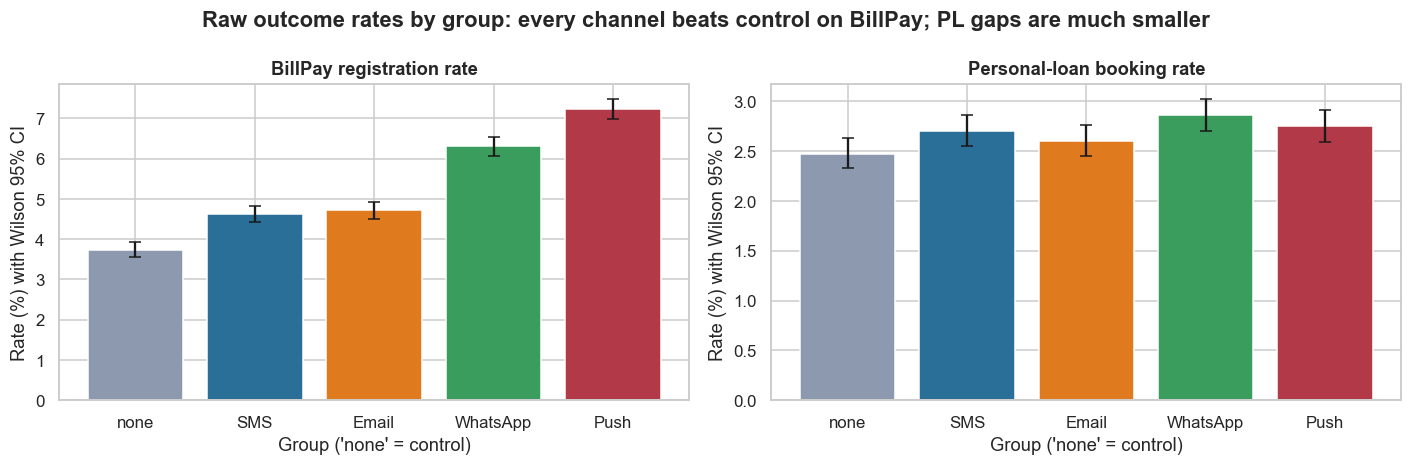

,billpay_registered,pl_booked
channel,,
none,3.7430,2.4720
SMS,4.6250,2.7000
Email,4.7130,2.6030
WhatsApp,6.3030,2.8550
Push,7.2260,2.7470


In [9]:
rates = df.groupby("channel")[["billpay_registered", "pl_booked"]].mean().reindex(GROUPS) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, col, title in [(axes[0], "billpay_registered", "BillPay registration rate"), (axes[1], "pl_booked", "Personal-loan booking rate")]:
    n = df.groupby("channel").size().reindex(GROUPS); k = df.groupby("channel")[col].sum().reindex(GROUPS)
    lo, hi = proportion_confint(k, n, method="wilson")
    ax.bar(GROUPS, rates[col], yerr=[rates[col] - lo * 100, hi * 100 - rates[col]], capsize=4, color=[PAL[g] for g in GROUPS])
    ax.set_xlabel("Group ('none' = control)"); ax.set_ylabel("Rate (%) with Wilson 95% CI"); ax.set_title(title)
plt.suptitle("Raw outcome rates by group: every channel beats control on BillPay; PL gaps are much smaller", fontweight="bold")
plt.tight_layout(); plt.show()
rates.round(3)

**Takeaway:** control customers register for BillPay at **3.7%**, and every channel beats that: SMS 4.6%, Email 4.7%, WhatsApp 6.3%, Push 7.2%. The confidence bars do not overlap with control. For personal loans the picture is much tighter: control 2.47% vs 2.60–2.86% across channels, with overlapping bars. Any channel ranking on loans must be tested formally, and may not be provable at all with this sample (Section 7.7).

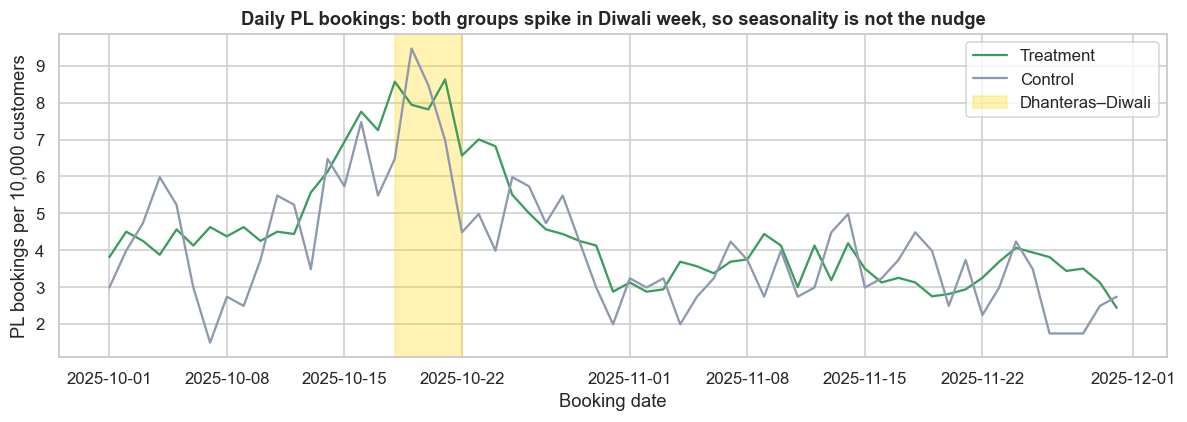

In [10]:
bk = df[df.pl_booked == 1].assign(d=lambda x: pd.to_datetime(x.pl_booking_date))
daily = bk.groupby(["d", "group"]).size().unstack().div(df.group.value_counts(), axis=1) * 1e4
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily.treatment, color="#3a9d5d", label="Treatment"); ax.plot(daily.index, daily.control, color="#8d99ae", label="Control")
ax.axvspan(pd.Timestamp("2025-10-18"), pd.Timestamp("2025-10-22"), color="gold", alpha=0.3, label="Dhanteras–Diwali")
ax.set_xlabel("Booking date"); ax.set_ylabel("PL bookings per 10,000 customers"); ax.set_title("Daily PL bookings: both groups spike in Diwali week, so seasonality is not the nudge")
ax.legend(); plt.tight_layout(); plt.show()

**Takeaway:** PL bookings spike in Diwali week in **both** groups. A before/after comparison would have credited the festive season to the campaign. Because control customers live through the same Diwali, the treatment-minus-control gap isolates the nudge effect. This is exactly the documented learning: "without [hold-outs], you only measure who would have bought anyway."

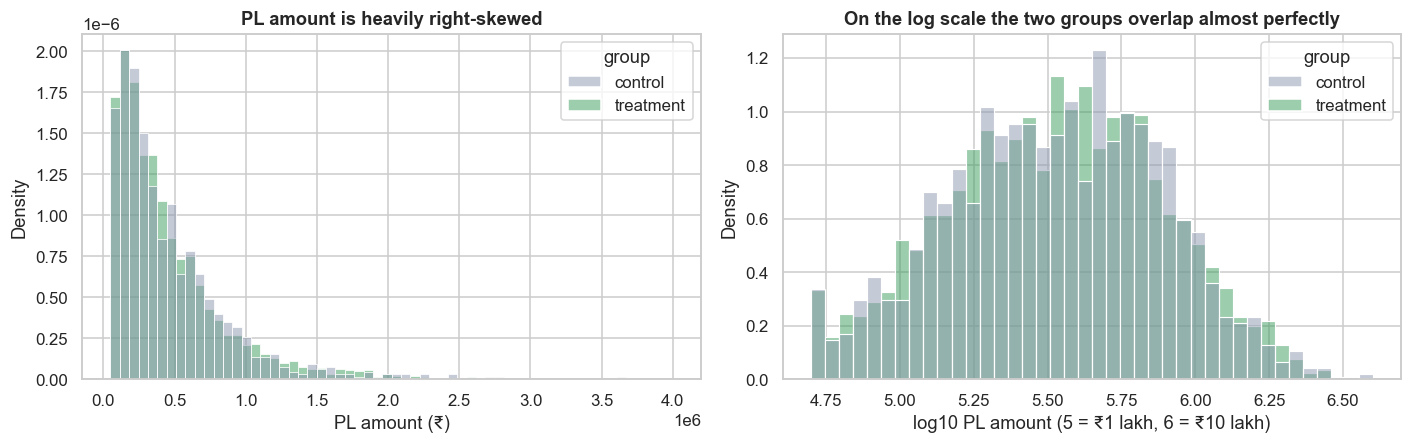

               count         mean          std         min          50%          90%            99%            max
group                                                                                                             
control     992.0000 465,056.0000 407,176.0000 50,000.0000 346,000.0000 944,900.0000 2,061,610.0000 3,632,000.0000
treatment 4,359.0000 466,975.0000 410,583.0000 50,000.0000 344,000.0000 986,200.0000 1,963,100.0000 4,000,000.0000


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
amt = df[df.pl_booked == 1]
sns.histplot(data=amt, x="pl_amount_inr", hue="group", stat="density", common_norm=False, bins=60, ax=axes[0], palette={"treatment": "#3a9d5d", "control": "#8d99ae"})
axes[0].set_xlabel("PL amount (₹)"); axes[0].set_ylabel("Density"); axes[0].set_title("PL amount is heavily right-skewed")
sns.histplot(data=amt, x=np.log10(amt.pl_amount_inr), hue="group", stat="density", common_norm=False, bins=40, ax=axes[1], palette={"treatment": "#3a9d5d", "control": "#8d99ae"})
axes[1].set_xlabel("log10 PL amount (5 = ₹1 lakh, 6 = ₹10 lakh)"); axes[1].set_ylabel("Density"); axes[1].set_title("On the log scale the two groups overlap almost perfectly")
plt.tight_layout(); plt.show()
print(amt.groupby("group").pl_amount_inr.describe(percentiles=[.5, .9, .99]).round(0))

**Takeaway:** loan amounts are strongly right-skewed. The mean is well above the median, pulled up by a long tail of ₹10–40 lakh loans. On a log scale the treatment and control distributions sit on top of each other. Early signal: the nudge changes **whether** people borrow, not **how much**. We test this formally in 7.3.

## 7. Statistical Analysis (core section)

Each test follows the template **(a) why, (b) assumptions, (c) result + effect size + CI, (d) power, (e) multiple testing, (f) business meaning.** All analyses use the full, SRM-clean assignment table (intention-to-treat).

### 7.1 Covariate balance — standardised mean differences (SMD)

**(a) Why SMD, not p-values?** Randomisation should make the groups alike on everything measured *before* the campaign. With 200,000 customers, a balance *p-value* flags trivial differences, so the field standard is the **standardised mean difference** = (mean_T − mean_C) / pooled SD. It is unit-free and independent of sample size. |SMD| < 0.1 means well balanced (D-3-09). We check the full table *and* the faulty export, to show how the logging bug breaks balance.

In [12]:
def smd_table(d, by="treated", covs=None):
    rows = []
    for c in covs:
        a, b = d.loc[d[by] == 1, c].astype(float), d.loc[d[by] == 0, c].astype(float)
        rows.append((c, a.mean(), b.mean(), (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)))
    return pd.DataFrame(rows, columns=["covariate", "mean treatment", "mean control", "SMD"]).set_index("covariate")

bal_df = df.assign(**{f"tier_{t[-1]}": (df.city_tier == t).astype(int) for t in ["Tier 1", "Tier 2", "Tier 3"]},
                   **{f"inc_{b}": (df.income_band == b).astype(int) for b in ["<5L", "5-10L", "10-25L", ">25L"]},
                   log_balance=np.log(df.avg_balance_inr), log_pre_rev=np.log(df.pre_revenue_inr_90d), log_pre_txn=np.log1p(df.pre_digital_txns_90d))
COVS = ["age", "log_balance", "tenure_months", "digital_active", "log_pre_txn", "log_pre_rev", "has_home_loan", "has_personal_loan",
        "credit_default_flag", "prior_campaign_success", "tier_1", "tier_3", "inc_<5L", "inc_>25L"]
smd_full = smd_table(bal_df, covs=COVS)
exp_df = bal_df[bal_df.in_campaign_export == 1]
smd_push_export = smd_table(exp_df[exp_df.channel.isin(["Push", "none"])], covs=COVS)["SMD"].rename("SMD Push vs control (export)")
smd_push_full = smd_table(bal_df[bal_df.channel.isin(["Push", "none"])], covs=COVS)["SMD"].rename("SMD Push vs control (full)")
bal = smd_full.join([smd_push_full, smd_push_export])
print(f"Max |SMD| treatment vs control (full table): {smd_full.SMD.abs().max():.4f}")
bal.round(4)

Max |SMD| treatment vs control (full table): 0.0108


,mean treatment,mean control,SMD,SMD Push vs control (full),SMD Push vs control (export)
covariate,,,,,
age,40.9082,40.8673,0.0039,0.0002,-0.0339
log_balance,10.7140,10.7161,-0.0018,-0.0047,-0.0060
tenure_months,72.6698,72.4047,0.0056,0.0098,0.0037
digital_active,0.7388,0.7365,0.0051,0.0075,0.1306
log_pre_txn,2.5678,2.5621,0.0070,0.0103,0.0929
log_pre_rev,6.6778,6.6698,0.0078,0.0087,0.0124
has_home_loan,0.5552,0.5545,0.0014,0.0066,0.0111
has_personal_loan,0.1614,0.1574,0.0108,0.0110,0.0106
credit_default_flag,0.0182,0.0168,0.0104,0.0073,0.0069


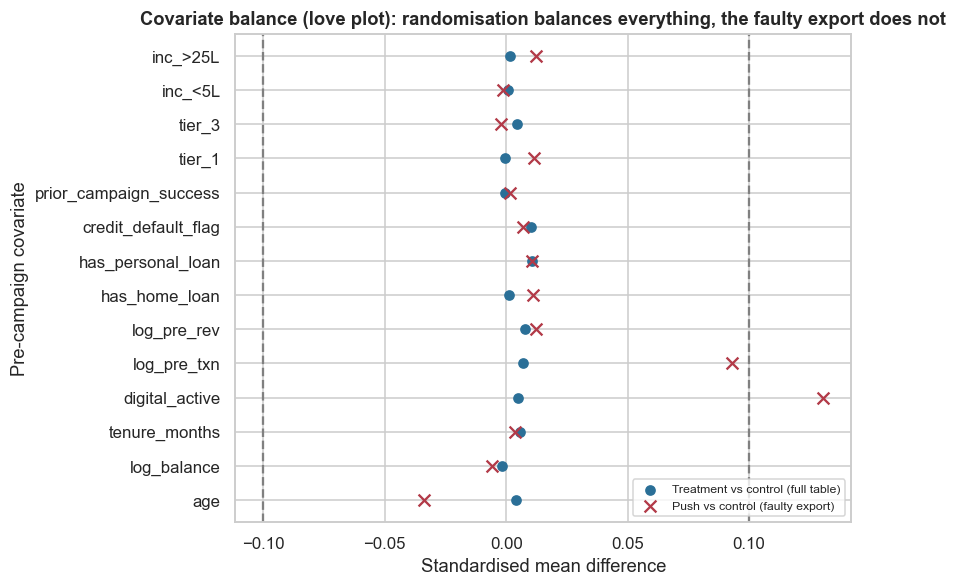

In [13]:
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(bal))
ax.scatter(bal["SMD"], y, color="#2a6f97", label="Treatment vs control (full table)", zorder=3)
ax.scatter(bal["SMD Push vs control (export)"], y, color="#b23a48", marker="x", s=60, label="Push vs control (faulty export)", zorder=3)
ax.axvline(0.1, ls="--", color="grey"); ax.axvline(-0.1, ls="--", color="grey")
ax.set_yticks(y); ax.set_yticklabels(bal.index); ax.set_xlabel("Standardised mean difference"); ax.set_ylabel("Pre-campaign covariate")
ax.set_title("Covariate balance (love plot): randomisation balances everything, the faulty export does not"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** in the full assignment table, **all 14 pre-campaign covariates have |SMD| ≤ 0.011**, far inside the 0.1 threshold. Randomisation worked, so any later difference in outcomes can be attributed to the nudge. In the **faulty export**, Push vs control is **imbalanced on app activity (SMD 0.13)** and pre-period digital transactions (0.09). The export made the Push group look more digital than the control group, so any comparison on that file would compare apples with oranges.

### 7.2 Two-proportion Z-tests: BillPay registration and PL conversion

**(a) Why?** Each outcome is binary and the groups are independent random samples, so the two-proportion Z-test is the textbook choice. It gives a direction and a CI for the gap, and Z² equals the 2×2 chi-square (D-3-10). We report:
- **absolute lift** = p_T − p_C in percentage points, with a Newcombe 95% CI;
- **relative lift** = p_T / p_C (the "1.5×" metric Axis reports), with a log-scale 95% CI;
- **Cohen's h** effect size.
**(b) Assumptions:** randomised, independent customers (✓); n·p ≥ 10 in each cell (✓, printed); SRM passed (✓); no interference between customers (one customer's nudge does not change another's behaviour; plausible for bill payments).

In [14]:
def two_prop(d, outcome, label):
    t, c = d[d.treated == 1][outcome], d[d.treated == 0][outcome]
    x = np.array([t.sum(), c.sum()]); n = np.array([len(t), len(c)])
    z, p = proportions_ztest(x, n)
    lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="newcomb", compare="diff")
    rlo, rhi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="log", compare="ratio")
    pt, pc = x / n
    return {"outcome": label, "rate treatment": pt, "rate control": pc, "abs lift (pp)": (pt - pc) * 100,
            "abs CI low": lo * 100, "abs CI high": hi * 100, "relative (T/C)": pt / pc, "rel CI low": rlo, "rel CI high": rhi,
            "Z": z, "p_value": p, "cohens_h": proportion_effectsize(pt, pc), "min n*p": int(min(x.min(), (n - x).min()))}

main = pd.DataFrame([two_prop(df, "billpay_registered", "BillPay registration"), two_prop(df, "pl_booked", "PL booking")]).set_index("outcome")
main.T

outcome,BillPay registration,PL booking
rate treatment,0.0571,0.0273
rate control,0.0374,0.0247
abs lift (pp),1.9705,0.2542
abs CI low,1.7494,0.0790
abs CI high,2.1852,0.4224
relative (T/C),1.5264,1.1028
rel CI low,1.4470,1.0303
rel CI high,1.6102,1.1805
Z,15.7268,2.8216
p_value,0.0000,0.0048


In [15]:
# What would the faulty export have told us about Push? (selection bias from the SRM)
def push_lift(d):
    t = d[d.channel == "Push"].billpay_registered.mean(); c = d[d.channel == "none"].billpay_registered.mean()
    return t / c
print(f"Push BillPay lift (T/C): faulty export = {push_lift(export):.3f}x  vs  full ITT table = {push_lift(df):.3f}x")

Push BillPay lift (T/C): faulty export = 2.027x  vs  full ITT table = 1.930x


**(c)–(f) Result and business meaning:** 
- **BillPay:** 3.74% → 5.71%, an absolute lift of **+1.97 pp (95% CI +1.75 to +2.19)** and a relative lift of **1.53× (95% CI 1.45–1.61×)**. Z = 15.7, p < 10⁻⁵⁰. The documented Axis figure of **1.5× sits inside our CI**. Cohen's h = 0.09 is "small" by textbook standards but large in business terms.
- **Personal loan:** 2.47% → 2.73%, an absolute lift of **+0.25 pp (95% CI +0.08 to +0.42)** and **+10.3% relative (95% CI +3.0% to +18.1%)**. Z = 2.82, **p = 0.005**. This matches the documented "+10%". The CI is wide, though: the true PL effect could be anything from marginal (+3%) to nearly double (+18%).
- **Selection bias from the SRM:** on the faulty export, Push's BillPay lift looks like **2.03×**. On the correct ITT table it is **1.93×**. The logging bug alone would have overstated Push by about 5%.

**What this means for the business:** the nudges **caused** both uplifts. This is not Diwali seasonality, because the randomised control lived through the same Diwali. The BillPay effect is large and certain. The PL effect is real, but every ₹ projection built on "PL +10%" should carry the +3% to +18% range.

### 7.3 PL amount among bookers: Welch's t-test vs Mann–Whitney U

**(a) Which test, and when?**
- **Welch's t-test** compares **means** without assuming equal variances. It answers "does the average loan size differ?", which is what matters for *₹ revenue*. It relies on the sampling distribution of the mean being roughly normal. With about 1,000 and 4,400 bookers the central limit theorem largely rescues skewed data, but heavy tails still widen the CI and can distort it.
- **Student's t-test** also assumes equal variances. We check that with **Levene's test**. Welch is the safer default because it loses almost nothing when variances are equal (D-3-11).
- **Mann–Whitney U** compares **ranks** ("is a random treated loan larger than a random control loan?"). It is robust to outliers and skew, but it does not test means, so it cannot be turned directly into ₹.
- **Rule:** if both agree, the conclusion is robust. If they disagree, the mean is being driven by a few large loans.
**(b) Assumption checks:** Shapiro–Wilk (on a random 500 per group) for raw and log amounts, Levene for equal variances.

In [16]:
a_t = amt.loc[amt.group == "treatment", "pl_amount_inr"].values; a_c = amt.loc[amt.group == "control", "pl_amount_inr"].values
sw = {f"Shapiro p raw ({g})": stats.shapiro(RNG_BOOT.choice(v, 500, replace=False)).pvalue for g, v in [("T", a_t), ("C", a_c)]}
sw.update({f"Shapiro p log ({g})": stats.shapiro(np.log(RNG_BOOT.choice(v, 500, replace=False))).pvalue for g, v in [("T", a_t), ("C", a_c)]})
lev = stats.levene(a_t, a_c, center="median")
welch = stats.ttest_ind(a_t, a_c, equal_var=False)
welch_ci = welch.confidence_interval(0.95)
student = stats.ttest_ind(a_t, a_c, equal_var=True)
welch_log = stats.ttest_ind(np.log(a_t), np.log(a_c), equal_var=False)
mwu = stats.mannwhitneyu(a_t, a_c, alternative="two-sided")
r_rb = 2 * mwu.statistic / (len(a_t) * len(a_c)) - 1
pooled_sd = np.sqrt(((len(a_t) - 1) * a_t.var(ddof=1) + (len(a_c) - 1) * a_c.var(ddof=1)) / (len(a_t) + len(a_c) - 2))
res73 = pd.Series({**sw, "skewness (T)": stats.skew(a_t), "Levene p (median-centred)": lev.pvalue,
                   "n bookers T": len(a_t), "n bookers C": len(a_c), "mean T (₹)": a_t.mean(), "mean C (₹)": a_c.mean(),
                   "median T (₹)": np.median(a_t), "median C (₹)": np.median(a_c),
                   "Welch t": welch.statistic, "Welch p": welch.pvalue, "Welch 95% CI low (₹)": welch_ci.low, "Welch 95% CI high (₹)": welch_ci.high,
                   "Cohen's d": (a_t.mean() - a_c.mean()) / pooled_sd, "Student t p": student.pvalue, "Welch p on log(amount)": welch_log.pvalue,
                   "Mann-Whitney U p": mwu.pvalue, "rank-biserial r": r_rb})
res73.to_frame("value")

,value
Shapiro p raw (T),0.0000
Shapiro p raw (C),0.0000
Shapiro p log (T),0.0029
Shapiro p log (C),0.0322
skewness (T),2.1143
Levene p (median-centred),0.8314
n bookers T,"4,359.0000"
n bookers C,992.0000
mean T (₹),"466,975.2237"
mean C (₹),"465,056.4516"


**Takeaway:** 
- **No effect on loan size.** Mean ₹4.67 lakh (treatment) vs ₹4.65 lakh (control); medians ₹3.44 vs ₹3.46 lakh. **Welch's t: p = 0.89**, 95% CI of the difference −₹26k to +₹30k (that is, within about ±6%), Cohen's d = 0.005. **Mann–Whitney: p = 0.85**, rank-biserial r = −0.004.
- **Assumption checks:** Shapiro–Wilk rejects normality for raw amounts and even for log amounts (skew 2.1). Levene's p = 0.83, so variances are equal, and Student's and Welch's t agree (p = 0.894 for both).
- **When to use which:** use **Welch** when you need a difference in *₹ means* (revenue) and samples are large. Use **Mann–Whitney** when outliers could dominate or samples are small, and the question is about the *typical* customer. Run both when they could disagree. Here they agree, so the conclusion is robust.

**For the business:** nudges bring *more borrowers*, not *bigger loans*. The guardrail holds: there is no sign of customers being pushed into smaller, uneconomic loans.

### 7.4 Bootstrap CI for the lift in revenue per customer

**(a) Why bootstrap?** Revenue per customer is ₹0 for about 94% of customers and a large number (₹10,000–₹3 lakh+) for the few who book a loan. That distribution is far too lumpy for a reliable normal-theory CI. The **bootstrap** resamples customers with replacement thousands of times, recomputes the lift each time, and reads the CI from the spread of the results. No distributional assumption is needed (D-3-12).
**Revenue definition (assumptions, D-3-12):** BillPay registration = **₹400** of 12-month value (bill-payment fees, float, retention); PL = **9% of the loan amount** as lifetime net revenue (interest margin plus processing fee, net of expected credit loss).
**(b) Assumptions:** customers are independent (✓), and the sample represents the population (✓, random assignment). 2,000 resamples, stratified by group.

In [17]:
rev_t = df.loc[df.treated == 1, "revenue_inr"].values; rev_c = df.loc[df.treated == 0, "revenue_inr"].values
B = 2000
boot_diff = np.empty(B); boot_rel = np.empty(B)
for b in range(B):
    mt = rev_t[RNG_BOOT.integers(0, len(rev_t), len(rev_t))].mean(); mc = rev_c[RNG_BOOT.integers(0, len(rev_c), len(rev_c))].mean()
    boot_diff[b], boot_rel[b] = mt - mc, mt / mc - 1
diff = rev_t.mean() - rev_c.mean()
se_norm = np.sqrt(rev_t.var(ddof=1) / len(rev_t) + rev_c.var(ddof=1) / len(rev_c))
print(f"Revenue per customer: treatment ₹{rev_t.mean():,.1f} | control ₹{rev_c.mean():,.1f} | share of customers with revenue 0: {np.mean(df.revenue_inr == 0):.1%}")
print(f"Lift = ₹{diff:,.2f} per customer; bootstrap 95% CI [₹{np.percentile(boot_diff, 2.5):,.2f}, ₹{np.percentile(boot_diff, 97.5):,.2f}]")
print(f"Normal-theory 95% CI (for comparison) [₹{diff - 1.96 * se_norm:,.2f}, ₹{diff + 1.96 * se_norm:,.2f}]")
print(f"Relative lift = {rev_t.mean() / rev_c.mean() - 1:+.1%}; bootstrap 95% CI [{np.percentile(boot_rel, 2.5):+.1%}, {np.percentile(boot_rel, 97.5):+.1%}]")
print(f"Bootstrap P(lift <= 0) = {np.mean(boot_diff <= 0):.4f}")

Revenue per customer: treatment ₹1,168.7 | control ₹1,049.7 | share of customers with revenue 0: 92.1%
Lift = ₹119.00 per customer; bootstrap 95% CI [₹25.86, ₹213.37]
Normal-theory 95% CI (for comparison) [₹22.87, ₹215.12]
Relative lift = +11.3%; bootstrap 95% CI [+2.3%, +21.8%]
Bootstrap P(lift <= 0) = 0.0105


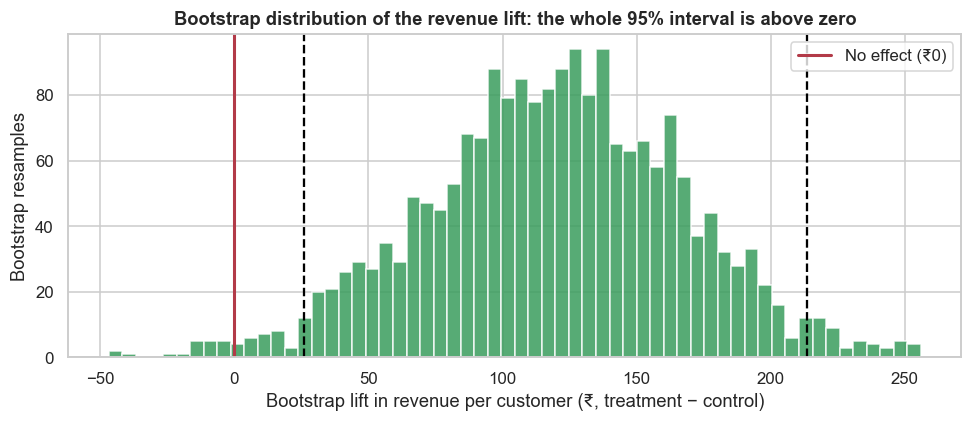

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(boot_diff, bins=60, color="#3a9d5d", alpha=0.85)
for q in np.percentile(boot_diff, [2.5, 97.5]):
    ax.axvline(q, color="black", ls="--")
ax.axvline(0, color="#b23a48", lw=2, label="No effect (₹0)")
ax.set_xlabel("Bootstrap lift in revenue per customer (₹, treatment − control)"); ax.set_ylabel("Bootstrap resamples")
ax.set_title("Bootstrap distribution of the revenue lift: the whole 95% interval is above zero"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** 
- Revenue per customer is **₹1,169 (treatment) vs ₹1,050 (control)**. The lift is **₹119 per customer (bootstrap 95% CI ₹26–₹213)**, or **+11.3% (CI +2.3% to +21.8%)**. Only 1% of bootstrap resamples show no gain.
- The normal-theory CI is similar (₹23–₹215) because n is very large. With 92% zeros, the bootstrap is still the safer default.
- The interval is wide (±₹94 around ₹119), because a few large personal loans dominate revenue.

**For the business:** across the 1.6 lakh nudged customers, that is **≈ ₹1.9 crore of incremental revenue (CI ≈ ₹0.4–3.4 crore)** against about ₹7.9 lakh of campaign cost (≈ ₹4.9 per customer). Even the **lower bound (₹26 per customer) is about 5× the cost per customer**, so the pre-registered decision rule is met.

### 7.5 Channel comparison: one-way ANOVA vs Kruskal–Wallis, with post-hoc tests

**(a) Why both?** We compare **5 groups** (control + 4 channels) on revenue per customer. Repeated pairwise t-tests would inflate false positives, so we first run one omnibus test, then post-hoc pairwise tests with family-wise control.
- **One-way ANOVA** tests equal *means*. It assumes normal residuals and equal variances. **Welch's ANOVA** drops the equal-variance assumption.
- **Kruskal–Wallis** is the rank-based alternative and tests whether the distributions differ, without normality.
- **Post-hoc:** **Tukey HSD** after ANOVA (controls the family-wise error for all pairs of means); **Dunn's test with Holm** after Kruskal–Wallis (pairwise rank comparisons). Dunn is implemented directly from its formula with scipy, so no extra library is needed (D-3-13).
- **Effect sizes:** η² (share of revenue variance explained by group) for ANOVA; ε² for Kruskal–Wallis.
**(b) Assumption checks:** Levene for equal variances; normality is clearly violated (94% zeros), so ANOVA rests on the CLT with n ≈ 40,000 per group and is cross-checked with Kruskal–Wallis.
Because revenue is dominated by rare loans, we repeat the channel comparison on the **BillPay** outcome, where the channel signal is much stronger (chi-square + pairwise Z-tests, Holm).

In [19]:
groups = [df.loc[df.channel == g, "revenue_inr"].values for g in GROUPS]
lev5 = stats.levene(*groups, center="median")
f_classic = stats.f_oneway(*groups)
welch_anova = anova_oneway(groups, use_var="unequal")
kw = stats.kruskal(*groups)
N = sum(len(g) for g in groups); k = len(groups)
grand = df.revenue_inr.mean()
eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df.revenue_inr - grand) ** 2).sum()
eps2 = (kw.statistic - k + 1) / (N - k)
omni = pd.DataFrame({"statistic": [lev5.statistic, f_classic.statistic, welch_anova.statistic, kw.statistic],
                     "p_value": [lev5.pvalue, f_classic.pvalue, welch_anova.pvalue, kw.pvalue]},
                    index=["Levene (equal variances)", "One-way ANOVA (classic)", "Welch ANOVA (unequal var.)", "Kruskal–Wallis"])
print(f"Effect sizes: eta² = {eta2:.5f} | epsilon² (Kruskal) = {eps2:.5f}")
print("Mean revenue per customer by group (₹):", {g: round(v.mean(), 1) for g, v in zip(GROUPS, groups)})
omni

Effect sizes: eta² = 0.00005 | epsilon² (Kruskal) = 0.00228
Mean revenue per customer by group (₹): {'none': np.float64(1049.7), 'SMS': np.float64(1162.9), 'Email': np.float64(1092.8), 'WhatsApp': np.float64(1220.7), 'Push': np.float64(1198.5)}


,statistic,p_value
Levene (equal variances),2.5180,0.0392
One-way ANOVA (classic),2.5180,0.0392
Welch ANOVA (unequal var.),2.5814,0.0353
Kruskal–Wallis,460.2573,0.0000


In [20]:
tukey = pairwise_tukeyhsd(df.revenue_inr, df.channel, alpha=0.05)
tk = pd.DataFrame(tukey._results_table.data[1:], columns=tukey._results_table.data[0])

def dunn_holm(values, labels):
    """Dunn's test (with tie correction) for all pairs, Holm-adjusted."""
    rk = stats.rankdata(values); n = len(values)
    _, counts = np.unique(values, return_counts=True)
    tie = 1 - (counts ** 3 - counts).sum() / (n ** 3 - n)
    lab = np.asarray(labels); out = []
    levels = list(pd.unique(lab))
    for i, a in enumerate(levels):
        for b in levels[i + 1:]:
            ra, rb = rk[lab == a], rk[lab == b]
            se = np.sqrt(tie * n * (n + 1) / 12 * (1 / len(ra) + 1 / len(rb)))
            z = (ra.mean() - rb.mean()) / se
            out.append((a, b, ra.mean() - rb.mean(), z, 2 * stats.norm.sf(abs(z))))
    t = pd.DataFrame(out, columns=["group1", "group2", "mean-rank diff", "z", "p_raw"])
    t["p_holm"] = multipletests(t.p_raw, method="holm")[1]; t["reject (Holm)"] = t.p_holm < 0.05
    return t
dn = dunn_holm(df.revenue_inr.values, df.channel.values)
print("Tukey HSD (revenue per customer, ₹):"); print(tk.to_string(index=False))
print("\nDunn's test with Holm (revenue per customer):"); print(dn.round(4).to_string(index=False))

Tukey HSD (revenue per customer, ₹):
  group1   group2  meandiff  p-adj     lower    upper  reject
   Email     Push  105.6655 0.4701  -69.8155 281.1466   False
   Email      SMS   70.0475 0.8107 -104.9156 245.0105   False
   Email WhatsApp  127.9363 0.2686  -47.0366 302.9091   False
   Email     none  -43.0636 0.9626 -218.0527 131.9255   False
    Push      SMS  -35.6181 0.9814 -210.8374 139.6013   False
    Push WhatsApp   22.2707 0.9969 -152.9584 197.4998   False
    Push     none -148.7291 0.1400 -323.9745  26.5163   False
     SMS WhatsApp   57.8888 0.8955 -116.8216 232.5991   False
     SMS     none -113.1111 0.3937 -287.8378  61.6156   False
WhatsApp     none -170.9998 0.0586 -345.7363   3.7366   False

Dunn's test with Holm (revenue per customer):
group1   group2  mean-rank diff        z  p_raw  p_holm  reject (Holm)
 Email      SMS        -35.9096  -0.1887 0.8503  0.8503          False
 Email     none      1,027.4251   5.3990 0.0000  0.0000           True
 Email     Push     -

In [21]:
# BillPay by channel: chi-square across the 5 groups, then each channel vs control and channel vs channel (Holm)
tab = pd.crosstab(df.channel, df.billpay_registered).reindex(GROUPS)
chi2, p_chi, dof, exp_ = stats.chi2_contingency(tab)
print(f"BillPay × group chi-square: chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.3g}, min expected = {exp_.min():,.0f}, Cramér's V = {np.sqrt(chi2 / tab.values.sum()):.4f}")
pairs = []
for i, a in enumerate(GROUPS):
    for b in GROUPS[i + 1:]:
        xa, na = tab.loc[a, 1], tab.loc[a].sum(); xb, nb = tab.loc[b, 1], tab.loc[b].sum()
        z, p = proportions_ztest([xa, xb], [na, nb])
        pairs.append((a, b, (xa / na - xb / nb) * 100, (xa / na) / (xb / nb), z, p))
bp_pairs = pd.DataFrame(pairs, columns=["group1", "group2", "diff (pp)", "ratio", "Z", "p_raw"])
bp_pairs["p_holm"] = multipletests(bp_pairs.p_raw, method="holm")[1]; bp_pairs["reject (Holm)"] = bp_pairs.p_holm < 0.05
bp_pairs.round(4)

BillPay × group chi-square: chi2 = 629.0, dof = 4, p = 8.37e-135, min expected = 2,110, Cramér's V = 0.0561


,group1,group2,diff (pp),ratio,Z,p_raw,p_holm,reject (Holm)
0,none,SMS,-0.8820,0.8093,-6.2399,0.0000,0.0000,True
1,none,Email,-0.9699,0.7942,-6.8188,0.0000,0.0000,True
2,none,WhatsApp,-2.5596,0.5939,-16.5999,0.0000,0.0000,True
3,none,Push,-3.4825,0.5180,-21.6227,0.0000,0.0000,True
4,SMS,Email,-0.0880,0.9813,-0.5898,0.5553,0.5553,False
5,SMS,WhatsApp,-1.6777,0.7338,-10.4580,0.0000,0.0000,True
6,SMS,Push,-2.6006,0.6401,-15.5693,0.0000,0.0000,True
7,Email,WhatsApp,-1.5897,0.7478,-9.8556,0.0000,0.0000,True
8,Email,Push,-2.5126,0.6523,-14.9635,0.0000,0.0000,True
9,WhatsApp,Push,-0.9229,0.8723,-5.1921,0.0000,0.0000,True


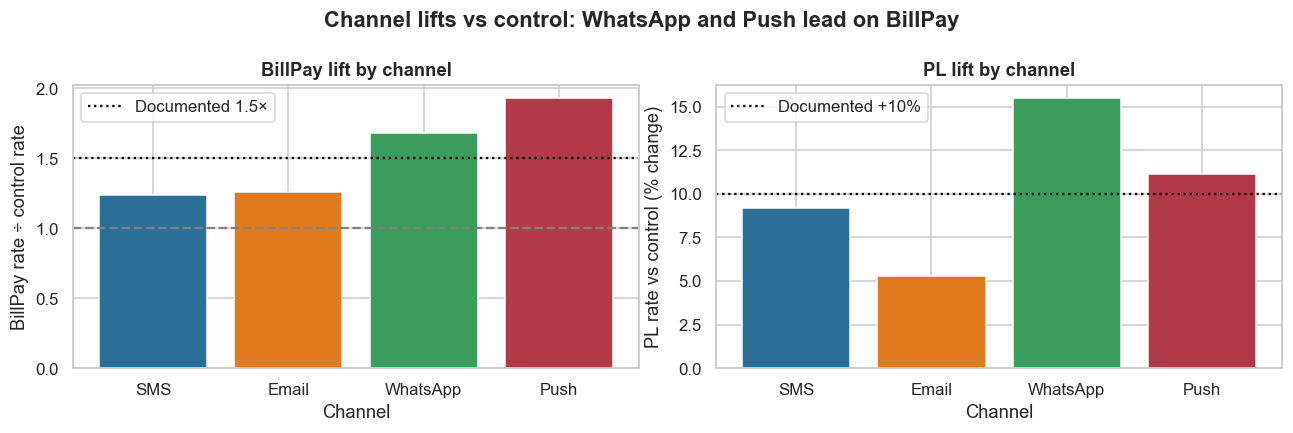

In [22]:
ch_rates = df.groupby("channel").agg(bp=("billpay_registered", "mean"), pl=("pl_booked", "mean"), n=("treated", "size")).reindex(GROUPS)
ch_rates["BillPay lift (x)"] = ch_rates.bp / ch_rates.loc["none", "bp"]
ch_rates["PL lift (%)"] = (ch_rates.pl / ch_rates.loc["none", "pl"] - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(CH, ch_rates.loc[CH, "BillPay lift (x)"], color=[PAL[c] for c in CH]); axes[0].axhline(1, color="grey", ls="--"); axes[0].axhline(1.5, color="black", ls=":", label="Documented 1.5×")
axes[0].set_xlabel("Channel"); axes[0].set_ylabel("BillPay rate ÷ control rate"); axes[0].set_title("BillPay lift by channel"); axes[0].legend()
axes[1].bar(CH, ch_rates.loc[CH, "PL lift (%)"], color=[PAL[c] for c in CH]); axes[1].axhline(10, color="black", ls=":", label="Documented +10%")
axes[1].set_xlabel("Channel"); axes[1].set_ylabel("PL rate vs control (% change)"); axes[1].set_title("PL lift by channel"); axes[1].legend()
plt.suptitle("Channel lifts vs control: WhatsApp and Push lead on BillPay", fontweight="bold"); plt.tight_layout(); plt.show()

**Takeaway:** 
- **Revenue per customer (₹):** control 1,050 · SMS 1,163 · Email 1,093 · WhatsApp 1,221 · Push 1,199.
- **ANOVA:** F = 2.52, p = 0.039 (classic); Welch ANOVA p = 0.035. The means differ somewhere, but **η² = 0.00005**: the group explains a negligible share of revenue variance. Levene's p = 0.039, so variances differ and Welch is the right ANOVA. (Levene's statistic is numerically identical to the ANOVA F here. That is not a bug: the median revenue is ₹0, so Levene's |x − median| is just x.)
- **Tukey HSD: no pair is significant** after correction (closest: WhatsApp vs control, +₹171, adjusted p = 0.059). Differences in *mean revenue* between channels are **not proven**.
- **Kruskal–Wallis:** H = 460, p ≈ 10⁻⁹⁸, ε² = 0.002. **Dunn–Holm:** every channel beats control; Push and WhatsApp beat SMS and Email and differ from each other; SMS vs Email does not differ.
- **Why do the two families disagree?** Ranks mostly capture *whether* a customer generated any revenue, which is driven by frequent BillPay registrations. Means are driven by rare, large loans, which are noisy. They answer different questions, and both are correct.
- **BillPay by channel:** χ² = 629, p ≈ 10⁻¹³⁵. Lifts are **Push 1.93× > WhatsApp 1.68× > Email 1.26× ≈ SMS 1.24×**. All pairs are Holm-significant except SMS vs Email (p = 0.56). PL lifts by channel are WhatsApp +15%, Push +11%, SMS +9%, Email +5%, but power for channel-vs-channel PL comparisons is only about 20% (Section 7.7).

**For the business:** the **robust** channel ranking (BillPay) is **Push > WhatsApp ≫ SMS ≈ Email**. On loans and revenue, WhatsApp looks best but that is *not proven*. Treat it as a hypothesis, not a budget fact.

### 7.6 CUPED: using pre-campaign behaviour to shrink the confidence interval

**Business view:** much of the variation in who registers or borrows was already predictable *before* the campaign (heavy digital users register more). **CUPED** (Controlled-experiment Using Pre-Experiment Data) removes that predictable part from the outcome, so the treatment effect is measured against less noise. Narrower CIs mean the same certainty with a smaller control group (a cheaper experiment), or more certainty with the same one.
**How:** Y_cuped = Y − θ·(X − mean(X)), with θ = cov(Y, X) / var(X), where X is a **pre-period** metric. It must be measured before randomisation, so the treatment cannot affect it, and the estimate stays unbiased. The variance falls by a factor of (1 − ρ²), where ρ = corr(Y, X).
- BillPay: X = `pre_digital_txns_90d` (log₁p). Revenue and PL: X = `pre_revenue_inr_90d` (log).
- **Engagement guardrail** `post_digital_txns_60d` (digital transactions during the campaign): X = `pre_digital_txns_90d`. This continuous, habit-driven metric is the textbook case where CUPED shines.
**(b) Assumption:** X is unaffected by treatment. We check this by testing X across groups; it should show no difference (D-3-14).

In [23]:
def cuped(d, y, x):
    X = d[x].values; Y = d[y].values.astype(float)
    theta = np.cov(Y, X)[0, 1] / X.var(ddof=1)
    yc = Y - theta * (X - X.mean())
    t = d.treated.values == 1
    def est(v):
        diff = v[t].mean() - v[~t].mean(); se = np.sqrt(v[t].var(ddof=1) / t.sum() + v[~t].var(ddof=1) / (~t).sum())
        return diff, se
    (d0, s0), (d1, s1) = est(Y), est(yc)
    rho = np.corrcoef(Y, X)[0, 1]
    xbal = stats.ttest_ind(X[t], X[~t], equal_var=False).pvalue
    return {"outcome": y, "covariate X": x, "corr(Y, X)": rho, "theta": theta, "X balanced? (Welch p)": xbal,
            "lift (raw)": d0, "CI half-width raw": 1.96 * s0, "lift (CUPED)": d1, "CI half-width CUPED": 1.96 * s1,
            "variance reduction": 1 - (s1 / s0) ** 2, "CI narrower by": 1 - s1 / s0,
            "equivalent extra sample": (s0 / s1) ** 2 - 1}
cdf = df.assign(log_pre_txn=np.log1p(df.pre_digital_txns_90d), log_pre_rev=np.log(df.pre_revenue_inr_90d))
cup = pd.DataFrame([cuped(cdf, "billpay_registered", "log_pre_txn"), cuped(cdf, "revenue_inr", "log_pre_rev"),
                    cuped(cdf, "pl_booked", "log_pre_rev"), cuped(cdf, "post_digital_txns_60d", "pre_digital_txns_90d")]).set_index("outcome")
cup.T

outcome,billpay_registered,revenue_inr,pl_booked,post_digital_txns_60d
covariate X,log_pre_txn,log_pre_rev,log_pre_rev,pre_digital_txns_90d
"corr(Y, X)",0.1249,0.0586,0.0360,0.8221
theta,0.0342,520.4400,0.0057,0.7393
X balanced? (Welch p),0.2086,0.1613,0.1613,0.1713
lift (raw),0.0197,118.9991,0.0025,0.4799
CI half-width raw,0.0022,96.1259,0.0017,0.1286
lift (CUPED),0.0195,114.8393,0.0025,0.4037
CI half-width CUPED,0.0022,95.9708,0.0017,0.0727
variance reduction,0.0105,0.0032,0.0012,0.6806
CI narrower by,0.0053,0.0016,0.0006,0.4349


**Takeaway:** 
- **Rare conversions (BillPay, PL, revenue):** pre-period behaviour correlates only weakly with them (ρ = 0.04–0.12), so CUPED reduces variance by just **0.1–1%** and the CIs barely change. CUPED is unbiased (the estimates hardly move), but here it gives no meaningful precision gain.
- **Engagement guardrail (digital transactions during the campaign):** ρ = 0.82 with the pre-period, so **variance falls by 68%** and the CI half-width shrinks from 0.13 to 0.07 transactions (**43% narrower**). That is **equivalent to having about 3× as many customers**. The lift estimate moves from +0.48 to +0.40 transactions per customer, within the raw CI. The CUPED estimate is the more precise one, because it removes a small chance pre-period imbalance.
- **Validity:** the pre-period covariates are balanced across arms (all p > 0.15), so the adjustment is legitimate.

**For the business:** CUPED is **free precision for habit-driven metrics** (transactions, balances, spend). For those, a control group about 3× smaller would give the same certainty, so less revenue is held back. For rare events like loans it is **not** a substitute for sample size.

### 7.7 Power analysis: was the 20% control group large enough?

**Pre-test question (what the team should have asked before launch):** with 200,000 customers split 80/20, what is the **minimum detectable effect (MDE)** at 80% power and α = 0.05, given pre-campaign baselines of about 3.7% (BillPay) and 2.5% (PL)? And is that small enough to detect the effects we hoped for (1.5× and +10%)?
**Formula:** for unequal groups, n_T = r·n_C, and the power calculation uses Cohen's h with `ratio = 4` (80/20).

In [24]:
pw = NormalIndPower()
n_c, n_t = (df.treated == 0).sum(), (df.treated == 1).sum()
def mde_rel(p0, nc, ratio):
    h = pw.solve_power(nobs1=nc, ratio=ratio, alpha=0.05, power=0.8)
    p1 = np.sin(np.arcsin(np.sqrt(p0)) + h / 2) ** 2
    return p1 / p0 - 1
def power_for(p0, rel, nc, ratio):
    return pw.power(effect_size=proportion_effectsize(p0 * (1 + rel), p0), nobs1=nc, ratio=ratio, alpha=0.05)
p_bp0, p_pl0 = 0.037, 0.025
rows = [("BillPay, all treatment vs control", p_bp0, n_c, n_t / n_c, 0.50),
        ("PL, all treatment vs control", p_pl0, n_c, n_t / n_c, 0.10),
        ("PL, one channel vs control", p_pl0, n_c, (n_t / 4) / n_c, 0.10),
        ("PL, channel vs channel", p_pl0, n_t / 4, 1.0, 0.05),
        ("BillPay, channel vs channel", p_bp0 * 1.4, n_t / 4, 1.0, 0.10)]
pa = pd.DataFrame([(lab, p0, int(nc), round(r, 2), mde_rel(p0, nc, r), eff, power_for(p0, eff, nc, r)) for lab, p0, nc, r, eff in rows],
                  columns=["comparison", "baseline", "n (smaller arm)", "ratio", "MDE (relative)", "hoped-for effect", "power for hoped-for effect"])
pa

,comparison,baseline,n (smaller arm),ratio,MDE (relative),hoped-for effect,power for hoped-for effect
0,"BillPay, all treatment vs control",0.0370,40125,3.9800,0.0813,0.5000,1.0000
1,"PL, all treatment vs control",0.0250,40125,3.9800,0.1000,0.1000,0.7999
2,"PL, one channel vs control",0.0250,40125,1.0000,0.1274,0.1000,0.6000
3,"PL, channel vs channel",0.0250,39968,1.0000,0.1275,0.0500,0.2011
4,"BillPay, channel vs channel",0.0518,39968,1.0000,0.0865,0.1000,0.8979


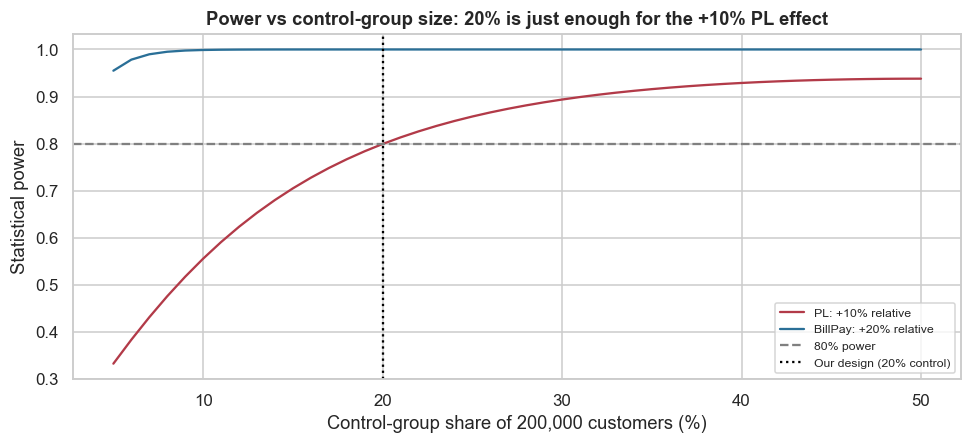

In [25]:
shares = np.linspace(0.05, 0.5, 46)
fig, ax = plt.subplots(figsize=(9, 4.2))
for p0, rel, lab, c in [(p_pl0, 0.10, "PL: +10% relative", "#b23a48"), (p_bp0, 0.20, "BillPay: +20% relative", "#2a6f97")]:
    ax.plot(shares * 100, [power_for(p0, rel, 200_000 * s, (1 - s) / s) for s in shares], color=c, label=lab)
ax.axhline(0.8, ls="--", color="grey", label="80% power"); ax.axvline(20, ls=":", color="black", label="Our design (20% control)")
ax.set_xlabel("Control-group share of 200,000 customers (%)"); ax.set_ylabel("Statistical power")
ax.set_title("Power vs control-group size: 20% is just enough for the +10% PL effect"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** 
- **BillPay (all treatment vs control):** MDE = **8% relative** at 80% power, so the hoped-for 1.5× was detectable with ~100% power. That part of the test was **over-powered**: a much smaller hold-out would have sufficed.
- **PL (all treatment vs control):** MDE = **10.0% relative**, so power for the documented +10% = **80%**. **The 20% control was just enough, with no margin.** A somewhat smaller true effect would probably have been missed. The power curve shows power reaching 80% at about a 20% control share.
- **PL per channel vs control:** MDE 12.7%, power 60%. **PL channel vs channel:** power about 20% for a 5% gap. **This experiment cannot rank channels on loans.**
- **BillPay channel vs channel:** MDE 8.7%, power about 90% for a 10% gap, so channel rankings on BillPay are trustworthy.

**For the business:** yes, the 20% control was large enough for the headline questions. For loan-focused campaigns it is the minimum. To compare channels on loans, each channel would need roughly 6–7× more customers, or a longer campaign.

### 7.8 Segment-level lift (heterogeneity), with multiple-testing control

**Business view:** "Does the nudge work better for young customers? For Tier-3? For app users?" These are natural questions, and also the easiest way to **fool ourselves**. Slice 200,000 customers into enough segments and some will show a "significant" lift by pure chance. Present only those, and we have **p-hacked** the result.

**Safeguards (D-3-15):**
1. Segments were **pre-specified** in Section 3: age band, income band, city tier, app activity, tenure band.
2. **Formal interaction test** per dimension. This asks the right question: does the lift *differ* across segments? (A significant lift in segment A and a non-significant one in segment B does **not** prove that A and B differ.) We test on **two scales**, because they answer different business questions:
   - **odds / relative scale:** logistic regression, treatment × segment vs treatment + segment, likelihood-ratio test. *"Is the lift **multiplier** different?"*
   - **additive / percentage-point scale:** linear probability model with robust (HC1) standard errors, Wald test of the interaction terms. *"Are the **extra registrations per customer** different?"* This is the scale that drives ₹ and targeting decisions.
3. **Holm** (family-wise) and **Benjamini–Hochberg** (false discovery rate) corrections across all segment-level lift tests.

In [26]:
seg_df = df.assign(tenure_band=pd.cut(df.tenure_months, [0, 24, 84, 400], labels=["<2y", "2-7y", "7y+"]).astype(str),
                   app=np.where(df.digital_active == 1, "app-active", "app-inactive"))
DIMS = {"age_band": "Age", "income_band": "Income", "city_tier": "City tier", "app": "App activity", "tenure_band": "Tenure"}
rows, inter = [], []
for dim, lab in DIMS.items():
    for lvl, g in seg_df.groupby(dim):
        r = two_prop(g, "billpay_registered", f"{lab}: {lvl}")
        rows.append((lab, lvl, len(g), r["rate control"], r["rate treatment"], r["relative (T/C)"], r["abs lift (pp)"], r["abs CI low"], r["abs CI high"], r["p_value"]))
    m0 = smf.logit(f"billpay_registered ~ treated + C({dim})", data=seg_df).fit(disp=0)
    m1 = smf.logit(f"billpay_registered ~ treated * C({dim})", data=seg_df).fit(disp=0)
    lr = 2 * (m1.llf - m0.llf); dfx = m1.df_model - m0.df_model
    lpm = smf.ols(f"billpay_registered ~ treated * C({dim})", data=seg_df).fit(cov_type="HC1")     # additive (pp) scale
    names = [n for n in lpm.params.index if n.startswith("treated:")]
    Rm = np.zeros((len(names), len(lpm.params))); Rm[np.arange(len(names)), [list(lpm.params.index).index(n) for n in names]] = 1
    w = lpm.wald_test(Rm, scalar=True)
    inter.append((lab, lr, dfx, stats.chi2.sf(lr, dfx), float(w.statistic), float(w.pvalue)))
seg = pd.DataFrame(rows, columns=["dimension", "segment", "n", "control rate", "treatment rate", "lift (x)", "abs lift (pp)", "CI low", "CI high", "p_raw"])
seg["p_holm"] = multipletests(seg.p_raw, method="holm")[1]; seg["p_BH"] = multipletests(seg.p_raw, method="fdr_bh")[1]
inter = pd.DataFrame(inter, columns=["dimension", "LR stat (odds scale)", "df", "p odds scale", "Wald chi2 (pp scale)", "p pp scale"])
inter["p_holm odds"] = multipletests(inter["p odds scale"], method="holm")[1]
inter["p_holm pp"] = multipletests(inter["p pp scale"], method="holm")[1]
print("Interaction tests (does the BillPay lift differ across levels?):"); print(inter.round(5).to_string(index=False))
seg.round(4)

Interaction tests (does the BillPay lift differ across levels?):
   dimension  LR stat (odds scale)     df  p odds scale  Wald chi2 (pp scale)  p pp scale  p_holm odds  p_holm pp
         Age                1.0758 2.0000        0.5840               14.5825      0.0007       1.0000     0.0020
      Income                2.6731 4.0000        0.6139               24.3482      0.0001       1.0000     0.0003
   City tier                0.2203 2.0000        0.8957                1.1140      0.5729       1.0000     0.5729
App activity                1.3412 1.0000        0.2468              100.4579      0.0000       0.9893     0.0000
      Tenure                3.2403 2.0000        0.1979                3.4337      0.1796       0.9893     0.3593


,dimension,segment,n,control rate,treatment rate,lift (x),abs lift (pp),CI low,CI high,p_raw,p_holm,p_BH
0,Age,18-34,66623,0.0440,0.0693,1.5735,2.5241,2.1048,2.9243,0.0000,0.0000,0.0000
1,Age,35-54,108306,0.0362,0.0540,1.4910,1.7786,1.4821,2.0632,0.0000,0.0000,0.0000
2,Age,55+,25071,0.0252,0.0384,1.5236,1.3207,0.7843,1.8048,0.0000,0.0000,0.0000
3,Income,10-25L,50625,0.0396,0.0635,1.6029,2.3885,1.9273,2.8244,0.0000,0.0000,0.0000
4,Income,5-10L,54989,0.0338,0.0488,1.4466,1.5077,1.1037,1.8882,0.0000,0.0000,0.0000
5,Income,<5L,52432,0.0264,0.0409,1.5477,1.4486,1.0748,1.7973,0.0000,0.0000,0.0000
6,Income,>25L,38026,0.0544,0.0829,1.5239,2.8505,2.2370,3.4310,0.0000,0.0000,0.0000
7,Income,Unknown,3928,0.0439,0.0577,1.3157,1.3852,-0.4601,2.8920,0.1296,0.1296,0.1296
8,City tier,Tier 1,98980,0.0399,0.0607,1.5228,2.0847,1.7591,2.3974,0.0000,0.0000,0.0000
9,City tier,Tier 2,62816,0.0342,0.0531,1.5533,1.8933,1.5101,2.2561,0.0000,0.0000,0.0000


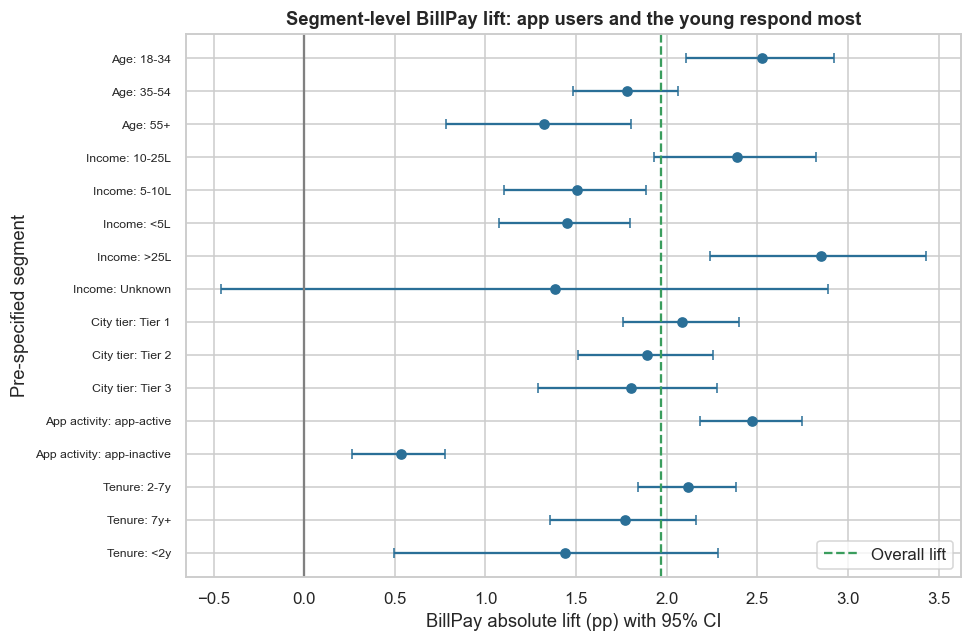

In [27]:
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(seg))[::-1]
ax.errorbar(seg["abs lift (pp)"], yy, xerr=[seg["abs lift (pp)"] - seg["CI low"], seg["CI high"] - seg["abs lift (pp)"]], fmt="o", color="#2a6f97", capsize=3)
ax.axvline(main.loc["BillPay registration", "abs lift (pp)"], color="#3a9d5d", ls="--", label="Overall lift")
ax.axvline(0, color="grey")
ax.set_yticks(yy); ax.set_yticklabels(seg.dimension + ": " + seg.segment.astype(str), fontsize=8)
ax.set_xlabel("BillPay absolute lift (pp) with 95% CI"); ax.set_ylabel("Pre-specified segment")
ax.set_title("Segment-level BillPay lift: app users and the young respond most"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway and p-hacking warning:** 
- **Per-segment lifts:** 15 of 16 pre-specified segment lifts are significant after Holm. The exception is income "Unknown" (n = 3.9k). Every lift is positive.
- **Odds (relative) scale:** **no interaction is significant** (all p ≥ 0.20). The lift *multiplier* (≈ 1.5×) is remarkably similar across ages, incomes, tiers, app activity and tenure.
- **Additive (percentage-point) scale:** **app activity, income and age differ significantly** (Holm p < 0.001, 0.0003 and 0.002). City tier (p = 0.57) and tenure (p = 0.36) do not.
  - App-active customers gain **+2.47 pp vs +0.53 pp** for app-inactive ones: 4.6× more extra registrations per nudge, because their baseline is 3.5× higher (4.6% vs 1.3%).
  - 18–34 year-olds gain +2.52 pp vs +1.32 pp for 55+. Income above ₹25 lakh gains +2.85 pp vs +1.45 pp below ₹5 lakh.
- **Reading:** the nudge roughly **multiplies each customer's existing propensity by about 1.5**, so the *absolute* payoff is largest where the baseline is highest. That is exactly what the uplift model below exploits.

**⚠️ p-hacking warning:** we ran 16 segment tests and 10 interaction tests. At 5% each, about 1.3 false positives are expected by chance alone. Had we tried, say, 10 dimensions × 2 scales × 4 outcomes and reported only the "winners", we could have told a convincing but false story ("WhatsApp works best for Tier-2 women aged 35–44"). **The rules:** pre-register segments; correct for multiple testing (Holm for decisions, BH for exploration); require a significant *interaction* before claiming that segments differ; and confirm any segment strategy in the next randomised wave.

## 8. ML Section — T-learner uplift model (two logistic regressions) and the Qini curve

**Business view:** instead of asking "does the nudge work on average?", an **uplift model** asks, for each customer, *"how much more likely is this customer to register **because** we nudge them?"* We then nudge the customers with the highest uplift first. The goal is to stop paying to nudge (a) people who would register anyway ("sure things") and (b) people who never will ("lost causes").

**T-learner:** fit one logistic model on treated customers and one on control customers, using the same pre-campaign features. Predicted uplift = P(register | treated) − P(register | control). Train on 50%, evaluate on the other 50% (D-3-16).

**Qini curve:** rank test customers by predicted uplift and walk down the list. At each point, plot the *incremental* registrations captured so far: treated registrations − control registrations × (n treated / n control). A model better than random bows above the diagonal. The **Qini coefficient** is the area between the curve and the random line.

In [28]:
FEATS = ["age", "income_idx", "digital_active", "log_pre_txn", "log_pre_rev", "tenure_months", "has_home_loan", "has_personal_loan",
         "prior_campaign_success", "tier1", "tier3", "young", "senior"]
ml = cdf.assign(income_idx=cdf.income_idx.fillna(1), tier1=(cdf.city_tier == "Tier 1").astype(int), tier3=(cdf.city_tier == "Tier 3").astype(int),
                young=(cdf.age < 35).astype(int), senior=(cdf.age >= 55).astype(int))
tr, te = train_test_split(ml, test_size=0.5, stratify=ml.treated, random_state=SEED)
mu = tr[FEATS].mean(); sd = tr[FEATS].std()
Z = lambda d: (d[FEATS] - mu) / sd
m_t = LogisticRegression(max_iter=2000).fit(Z(tr[tr.treated == 1]), tr.loc[tr.treated == 1, "billpay_registered"])
m_c = LogisticRegression(max_iter=2000).fit(Z(tr[tr.treated == 0]), tr.loc[tr.treated == 0, "billpay_registered"])
te = te.assign(uplift=m_t.predict_proba(Z(te))[:, 1] - m_c.predict_proba(Z(te))[:, 1])

def qini(d, score):
    d = d.sort_values(score, ascending=False)
    t = d.treated.values; y = d.billpay_registered.values
    ct, cc = np.cumsum(t), np.cumsum(1 - t); yt, yc = np.cumsum(y * t), np.cumsum(y * (1 - t))
    inc = yt - yc * np.divide(ct, cc, out=np.zeros_like(ct, dtype=float), where=cc > 0)
    frac = np.arange(1, len(d) + 1) / len(d)
    return frac, inc
frac, inc = qini(te, "uplift")
rand_line = frac * inc[-1]
qini_coef = np.trapezoid(inc - rand_line, frac) / inc[-1]
te["decile"] = pd.qcut(te.uplift.rank(method="first", ascending=False), 10, labels=range(1, 11))
dec = te.groupby("decile", observed=True).apply(lambda g: pd.Series({
    "predicted uplift (pp)": g.uplift.mean() * 100,
    "observed uplift (pp)": (g.loc[g.treated == 1, "billpay_registered"].mean() - g.loc[g.treated == 0, "billpay_registered"].mean()) * 100,
    "app-active share": g.digital_active.mean(), "n": len(g)}), include_groups=False)
k40 = int(0.4 * len(te)); share40 = inc[k40 - 1] / inc[-1]
print(f"Qini coefficient (normalised) = {qini_coef:.3f} | Targeting the top 40% by uplift captures {share40:.0%} of all incremental registrations")
print(f"Spearman corr(predicted, observed uplift by decile) = {stats.spearmanr(dec['predicted uplift (pp)'], dec['observed uplift (pp)']).statistic:.2f}")
dec.round(3)

Qini coefficient (normalised) = 0.142 | Targeting the top 40% by uplift captures 57% of all incremental registrations
Spearman corr(predicted, observed uplift by decile) = 0.83


,predicted uplift (pp),observed uplift (pp),app-active share,n
decile,,,,
1,4.9750,3.3340,1.0000,"10,000.0000"
2,3.4620,3.7420,1.0000,"10,000.0000"
3,2.8080,1.5770,0.9990,"10,000.0000"
4,2.3350,2.4960,0.9950,"10,000.0000"
5,1.9370,2.2730,0.9840,"10,000.0000"
6,1.5650,1.9570,0.9430,"10,000.0000"
7,1.1880,2.4110,0.7850,"10,000.0000"
8,0.8230,0.9110,0.4570,"10,000.0000"
9,0.5180,0.4270,0.1660,"10,000.0000"


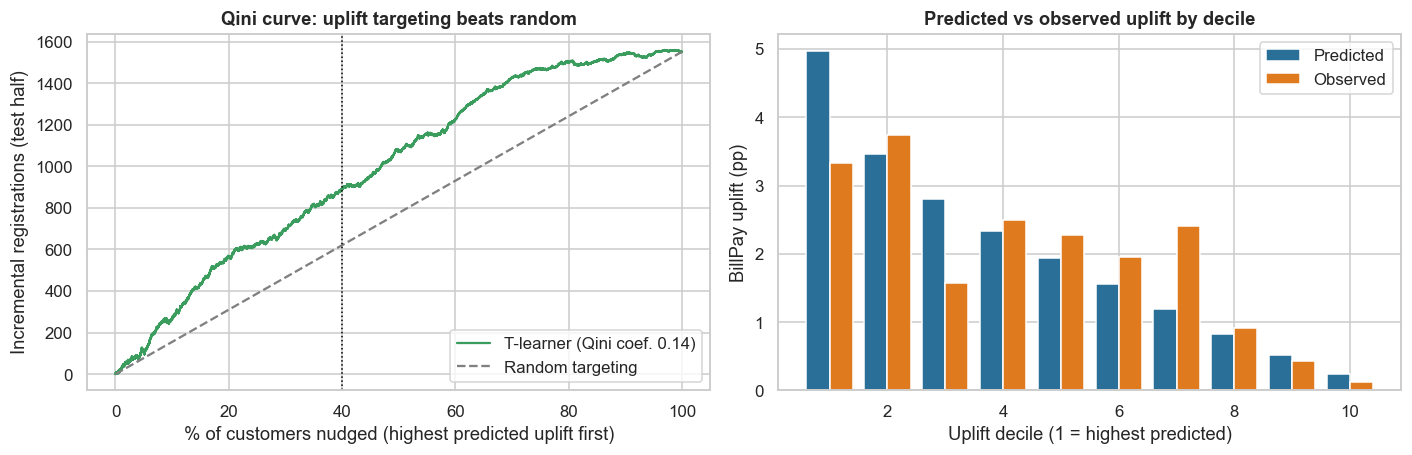

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(frac * 100, inc, color="#3a9d5d", label=f"T-learner (Qini coef. {qini_coef:.2f})")
axes[0].plot(frac * 100, rand_line, "--", color="grey", label="Random targeting")
axes[0].axvline(40, color="black", ls=":", lw=1)
axes[0].set_xlabel("% of customers nudged (highest predicted uplift first)"); axes[0].set_ylabel("Incremental registrations (test half)")
axes[0].set_title("Qini curve: uplift targeting beats random"); axes[0].legend(loc="lower right")
axes[1].bar(dec.index.astype(int) - 0.2, dec["predicted uplift (pp)"], 0.4, color="#2a6f97", label="Predicted")
axes[1].bar(dec.index.astype(int) + 0.2, dec["observed uplift (pp)"], 0.4, color="#e07a1f", label="Observed")
axes[1].set_xlabel("Uplift decile (1 = highest predicted)"); axes[1].set_ylabel("BillPay uplift (pp)"); axes[1].set_title("Predicted vs observed uplift by decile"); axes[1].legend()
plt.tight_layout(); plt.show()

**Takeaway:** 
- **Qini coefficient = 0.14.** Nudging the **top 40% of customers ranked by predicted uplift captures 57% of all incremental registrations**, against 40% for random targeting: about 1.4× the targeting efficiency.
- The predicted and observed uplift per decile line up well (Spearman 0.83). The top deciles are about 100% app-active customers. The bottom two deciles are mostly app-inactive, with observed uplift of only 0.1–0.4 pp.
- The model largely rediscovers a simple rule: **app-active, digitally busy, younger, higher-income customers respond most in absolute terms.** That is easy to explain and to turn into a targeting rule.

**For the business:** if fatigue or budget limits how many customers we can nudge, rank them by uplift, not by propensity. A propensity model would target "sure things" who register anyway.

## 9. Business Translation — incremental revenue, cost, ROI per channel, budget reallocation

**Step-by-step logic (per channel):**
1. Incremental registrations = (BillPay rate_channel − rate_control) × customers nudged on that channel. Same for PL bookings.
2. Incremental revenue = (revenue per customer_channel − revenue per customer_control) × customers nudged, with a bootstrap 95% CI.
3. Campaign cost = customers × 4 nudges × unit cost + a fixed creative/operations cost of ₹1.5 lakh per channel.
4. ROI = (incremental revenue − cost) ÷ cost.

**Assumptions (D-3-12, D-3-17):** BillPay value ₹400, PL net revenue 9% of the loan amount. Unit cost per message: SMS ₹0.25, Email ₹0.05, WhatsApp ₹0.85, Push ₹0.02 (typical Indian bulk rates, our assumption). Sensitivity: BillPay value ₹300–500, PL revenue 7–11%.

In [30]:
UNIT = {"SMS": 0.25, "Email": 0.05, "WhatsApp": 0.85, "Push": 0.02}; SENDS, FIXED = 4, 150_000
rc = df.loc[df.channel == "none", "revenue_inr"].values
roi_rows = []
for c in CH:
    g = df[df.channel == c]; rv = g.revenue_inr.values; n = len(g)
    bs = np.array([rv[RNG_BOOT.integers(0, n, n)].mean() - rc[RNG_BOOT.integers(0, len(rc), len(rc))].mean() for _ in range(1000)])
    lift = rv.mean() - rc.mean(); cost = n * SENDS * UNIT[c] + FIXED
    inc_bp = (g.billpay_registered.mean() - df.loc[df.channel == "none", "billpay_registered"].mean()) * n
    inc_pl = (g.pl_booked.mean() - df.loc[df.channel == "none", "pl_booked"].mean()) * n
    roi_rows.append((c, n, inc_bp, inc_pl, lift, np.percentile(bs, 2.5), np.percentile(bs, 97.5), lift * n / 1e5,
                     np.percentile(bs, 2.5) * n / 1e5, cost / 1e5, (lift * n - cost) / cost, lift * n / cost))
roi = pd.DataFrame(roi_rows, columns=["channel", "customers", "incr. BillPay regs", "incr. PL bookings", "Δrevenue/cust ₹", "Δrev CI low ₹", "Δrev CI high ₹",
                                      "incr. revenue ₹ lakh", "incr. revenue (CI low) ₹ lakh", "cost ₹ lakh", "ROI", "revenue per ₹ cost"]).set_index("channel")
tot_rev = (rev_t.mean() - rc.mean()) * n_t; tot_cost = sum(roi.customers * SENDS * pd.Series(UNIT)) + FIXED * 4
print(f"Whole campaign: incremental revenue ₹{tot_rev / 1e5:,.1f} lakh vs cost ₹{tot_cost / 1e5:,.1f} lakh -> ROI {(tot_rev - tot_cost) / tot_cost:,.1f}x")
roi.round(2)

Whole campaign: incremental revenue ₹190.2 lakh vs cost ₹7.9 lakh -> ROI 23.2x


,customers,incr. BillPay regs,incr. PL bookings,Δrevenue/cust ₹,Δrev CI low ₹,Δrev CI high ₹,incr. revenue ₹ lakh,incr. revenue (CI low) ₹ lakh,cost ₹ lakh,ROI,revenue per ₹ cost
channel,,,,,,,,,,,
SMS,40149,354.1000,91.4100,113.1100,-5.9600,231.2400,45.4100,-2.3900,1.9000,22.8800,23.8800
Email,39909,387.0900,52.3400,43.0600,-71.7400,154.8700,17.1900,-28.6300,1.5800,9.8800,10.8800
WhatsApp,40140,"1,027.4400",153.6300,171.0000,41.5300,292.0300,68.6400,16.6700,2.8600,22.9600,23.9600
Push,39677,"1,381.7700",109.0800,148.7300,24.5600,274.6600,59.0100,9.7500,1.5300,37.5300,38.5300


In [31]:
# BillPay-only economics (the documented 1.5x product), where channel differences are statistically solid
bp_rows = []
for c in CH:
    r = roi.loc[c]; cost = r.customers * SENDS * UNIT[c] + FIXED
    bp_rows.append((c, r["incr. BillPay regs"], r["incr. BillPay regs"] * BILLPAY_VALUE / 1e5, cost / 1e5, cost / r["incr. BillPay regs"]))
bp_econ = pd.DataFrame(bp_rows, columns=["channel", "incr. BillPay regs", "BillPay value ₹ lakh", "cost ₹ lakh", "cost per incremental registration ₹"]).set_index("channel")
bp_econ.round(1)

,incr. BillPay regs,BillPay value ₹ lakh,cost ₹ lakh,cost per incremental registration ₹
channel,,,,
SMS,354.1000,1.4000,1.9000,537.0000
Email,387.1000,1.5000,1.6000,408.1000
WhatsApp,"1,027.4000",4.1000,2.9000,278.8000
Push,"1,381.8000",5.5000,1.5000,110.9000


In [32]:
# Budget reallocation: best channel per (app activity x age) cell, using observed BillPay lifts (in-sample estimate)
cells = df.assign(app=df.digital_active, age3=df.age_band)
ctrl = cells[cells.channel == "none"].groupby(["app", "age3"]).billpay_registered.mean()
cell_lift = cells[cells.treated == 1].groupby(["app", "age3", "channel"]).billpay_registered.mean().unstack().sub(ctrl, axis=0)
best = cell_lift.idxmax(axis=1); best_val = cell_lift.max(axis=1); avg_val = cell_lift.mean(axis=1)
cell_n = cells.groupby(["app", "age3"]).size()
realloc = pd.DataFrame({"customers": cell_n, "best channel": best, "lift if best (pp)": best_val * 100, "lift with random channel (pp)": avg_val * 100})
gain_regs = ((best_val - avg_val) * cell_n * 0.8).sum()
print(f"Sending each cell its best channel instead of a random one: ≈ {gain_regs:,.0f} more BillPay registrations "
      f"(+{gain_regs / ((avg_val * cell_n * 0.8).sum()):.0%} over random allocation) — in-sample estimate, to be confirmed in the next test")
realloc.round(2)

Sending each cell its best channel instead of a random one: ≈ 2,718 more BillPay registrations (+87% over random allocation) — in-sample estimate, to be confirmed in the next test


customers best channel  lift if best (pp)  lift with random channel (pp)
app age3                                                                           
0   18-34       9732     WhatsApp             1.9000                         1.1400
    35-54      29947     WhatsApp             0.8400                         0.4300
    55+        12656     WhatsApp             1.0100                         0.3100
1   18-34      56891         Push             5.3600                         2.7500
    35-54      78359         Push             4.1800                         2.2800
    55+        12415         Push             3.5100                         2.3600

**Sensitivity (best / base / worst)** for the whole campaign's net value, combining the revenue assumptions with the bootstrap CI of the lift:

In [33]:
sens = []
base_bp = (df.loc[df.treated == 1, "billpay_registered"].mean() - df.loc[df.treated == 0, "billpay_registered"].mean()) * n_t
base_pl_rev = (df.loc[df.treated == 1].pl_booked.mul(df.pl_amount_inr.fillna(0)).mean() - df.loc[df.treated == 0].pl_booked.mul(df.pl_amount_inr.fillna(0)).mean()) * n_t
lo_q, hi_q = np.percentile(boot_diff, [2.5, 97.5]) / diff
for lab, bpv, plr, q in [("Worst", 300, 0.07, lo_q), ("Base", 400, 0.09, 1.0), ("Best", 500, 0.11, hi_q)]:
    rev = (base_bp * bpv + base_pl_rev * plr) * q
    sens.append((lab, bpv, plr, round(q, 2), rev / 1e5, tot_cost / 1e5, (rev - tot_cost) / 1e5, (rev - tot_cost) / tot_cost))
pd.DataFrame(sens, columns=["scenario", "BillPay value ₹", "PL revenue %", "lift multiplier (CI)", "incr. revenue ₹ lakh", "cost ₹ lakh", "net value ₹ lakh", "ROI"]).set_index("scenario").round(2)

,BillPay value ₹,PL revenue %,lift multiplier (CI),incr. revenue ₹ lakh,cost ₹ lakh,net value ₹ lakh,ROI
scenario,,,,,,,
Worst,300,0.0700,0.2200,32.0800,7.8800,24.2100,3.0700
Base,400,0.0900,1.0000,190.2500,7.8800,182.3700,23.1500
Best,500,0.1100,1.7900,417.5700,7.8800,409.6900,52.0100


**Business reading:** 
- **Whole campaign:** ≈ **₹1.9 crore of incremental revenue** for ≈ **₹7.9 lakh of cost**, an ROI of about **23×** (base). Worst case ≈ 3× (₹24 lakh net: lower-bound lift, BillPay ₹300, PL 7%); best case ≈ 52×. **Even the worst case is profitable.**
- **By channel (revenue):** WhatsApp brings the most incremental revenue (₹68.6 lakh; CI lower bound ₹16.7 lakh > 0) at the highest cost. Push has the best ROI (≈ 38×; CI lower bound > 0). SMS (₹45 lakh) and especially Email (₹17 lakh, ROI ≈ 10×) have CIs that include zero.
- **Caution:** these per-channel revenue CIs are *not* adjusted for multiple comparisons, and they are dominated by loan noise (Tukey found no significant pair). The **hard** channel economics come from BillPay: the **cost per incremental registration** is **Push ₹111, WhatsApp ₹279, Email ₹408, SMS ₹537**.
- **Reallocation:** sending each (app activity × age) cell its best channel (app-active → Push, app-inactive → WhatsApp) instead of a random one would add ≈ **2,700 BillPay registrations (+87%)**. This is an in-sample estimate subject to the winner's curse, so expect less in practice.
- **The real constraint is not money:** messages cost ₹0.02–0.85, while a booked loan is worth tens of thousands of rupees. The binding constraint is **customer attention and fatigue** (opt-outs). The economic question is *which* message to send to *whom*, not whether to send.

## 10. Recommendation and Decision

**Decision against the pre-registered rule (Section 3):** the revenue lift is positive and its **lower 95% bound (₹26 per customer) exceeds the cost per customer (₹4.9)** ✅. Channel shifts are justified for BillPay (Holm-significant) ✅ but not yet for loans (under-powered) ⚠️.

**I recommend:**
1. **Continue funding the nudge programme.** The effect is causal (randomised), matches the documented 1.5× and +10%, and is profitable even in the worst case.
2. **Reallocate channels on the proven BillPay evidence:** **Push first for app-active customers** (cheapest, highest lift). **WhatsApp for app-inactive customers.** **Stop sending Push to inactive-app customers:** it cannot reach them (zero effect) and it broke the tracking logs. Keep Email as a low-cost supplementary touch. Use SMS where WhatsApp consent is unavailable.
3. **Target by uplift, not propensity:** when fatigue limits volume, nudge the top 40–60% by predicted uplift (the top 40% delivers 57% of the effect).
4. **Fix measurement:** log assignment at randomisation time. Add a **daily automated SRM check**. Keep a **permanent 10–20% hold-out**. Pre-register CUPED for engagement metrics.
5. **Next experiment (test, don't assume):** three arms, *optimised allocation* (uplift targeting + best channel) vs *today's random allocation* vs *control*. Size it with Section 7.7, and confirm the reallocation gain out-of-sample before scaling it nationally.

**KPIs to monitor after the change:** incremental BillPay and PL rates vs the hold-out (weekly, with CIs); revenue-per-customer lift (bootstrap CI); cost per incremental registration by channel; **opt-out and complaint rates by channel (guardrail)**; 90-day activity of nudged BillPay registrants; **early delinquency of nudged vs organic PL borrowers (credit-quality guardrail)**; daily SRM p-value.

## 11. Risks, Limitations and Next Steps

**Limits of the (semi-)synthetic data.**
- The customer *attributes* come from a real (Portuguese, 2008–2010) bank, but every *outcome* and every effect size is ours, calibrated to the two documented numbers (1.5× and +10%). The channel and segment patterns are **assumptions that illustrate the method**, not findings about Axis Bank's customers.
- **Bootstrapping 45,211 real customers to 200,000** repeats each real profile about 4 times. That is fine for the attribute mix, but it understates the true diversity of a 50M-customer base.
- Real campaigns have **message-level exposure data** (delivered, opened, clicked), **opt-outs and complaints**, and **multiple overlapping campaigns**. None is simulated. Opt-outs are a key guardrail that must be added.

**Method risks.**
- **ITT vs effect of exposure:** ITT measures the programme as run. The effect on customers *who actually received* a push is larger (the CACE / instrumental-variable estimate) and needs delivery logs.
- **Novelty and fatigue:** a two-month festive campaign may overstate long-run lift. Repeat the test off-season.
- **Interference:** if customers talk to each other (family accounts), control customers may be indirectly "treated", which biases the lift towards zero.
- **The reallocation estimate is in-sample:** it picks the best channel per cell and evaluates it on the same data (winner's curse). Validate it in the next randomised wave.

**What real data would change.** Real delivery/open logs would allow an exposure-adjusted effect. Real revenue would replace the ₹400 / 9% assumptions. With 17,000+ nudge variants, a **multi-armed-bandit allocation** (as in Case 1), with a permanent random hold-out, would beat a fixed A/B design.

**Next steps.** (1) Fix the tracking pipeline (log at assignment) and add a daily automated SRM alert. (2) Next wave: test the uplift-targeted, channel-optimised plan against today's random allocation, with CUPED pre-registered. (3) Add opt-out/complaint guardrails. (4) Measure 6-month retention of BillPay registrants (are nudged registrants as active as organic ones?).

## 12. Appendix

**Formulas used**

| Quantity | Formula |
|---|---|
| SRM test | χ² = Σ (O − E)² / E, E = designed share × N |
| SMD | (x̄_T − x̄_C) / √((s_T² + s_C²)/2) |
| Two-proportion Z | (p̂_T − p̂_C) / √(p̄(1 − p̄)(1/n_T + 1/n_C)) |
| Relative lift CI | exp(ln(p̂_T/p̂_C) ± 1.96·√((1 − p̂_T)/x_T + (1 − p̂_C)/x_C)) |
| Welch t | (x̄_T − x̄_C) / √(s_T²/n_T + s_C²/n_C), Welch–Satterthwaite df |
| Rank-biserial | 2U/(n_T·n_C) − 1 |
| η² (ANOVA) | SS_between / SS_total |
| ε² (Kruskal) | (H − k + 1)/(N − k) |
| Dunn z | (R̄_i − R̄_j) / √(C·N(N+1)/12·(1/n_i + 1/n_j)), C = tie correction |
| CUPED | Y* = Y − θ(X − X̄), θ = cov(Y, X)/var(X); Var(Y*) = Var(Y)(1 − ρ²) |
| Power (unequal groups) | Cohen's h with n_T = r·n_C; MDE solved for power 0.8 |
| T-learner uplift | τ̂(x) = P̂(Y=1 \| x, T=1) − P̂(Y=1 \| x, T=0) |
| Qini | Q(k) = Y_T(k) − Y_C(k)·N_T(k)/N_C(k) |
| ROI | (incremental revenue − cost) / cost |

**Glossary (simple English)**

| Term | Meaning |
|---|---|
| Treatment / control | Customers who got a nudge / who were deliberately left alone for comparison. |
| Randomisation | Assigning groups by chance, so the only systematic difference is the nudge. |
| Intention-to-treat (ITT) | Analyse everyone as assigned, even if the message never arrived. |
| SRM | Sample-ratio mismatch: group sizes differ from the design, which signals a data bug. |
| SMD | Standardised mean difference: a size-free measure of group imbalance. |
| Absolute vs relative lift | Percentage-point difference vs ratio ("1.5×"). |
| Welch t-test | Compares means without assuming equal spread. |
| Mann–Whitney U | Compares groups by ranks; robust to skew and outliers. |
| Bootstrap | Resampling the data many times to see how much a result could vary. |
| ANOVA / Kruskal–Wallis | One test for "do any of these groups differ?" (means / ranks). |
| Tukey HSD / Dunn | Follow-up tests for which pairs differ, controlling false positives. |
| CUPED | Using pre-campaign behaviour to remove noise and narrow CIs. |
| Power / MDE | Chance of detecting a real effect / smallest effect we can reliably detect. |
| Heterogeneity | The effect differs between customer groups. |
| p-hacking | Slicing data until something looks significant, then reporting only that. |
| Holm / Benjamini–Hochberg | Corrections that keep false positives under control across many tests. |
| Uplift model / T-learner | Predicts how much a nudge changes each customer's behaviour, using two models. |
| Qini curve | Shows how many incremental conversions you capture by targeting top-uplift customers first. |
| ROI | Return on investment: net gain per ₹ spent. |